In [2]:
from rdkit import Chem

import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader, TensorDataset

import torch.nn as nn
import torch.nn.functional as F
from tqdm.auto import tqdm

from rdkit.Chem import rdMolDescriptors
from rdkit.Chem import Descriptors
from rdkit.Chem.rdMolDescriptors import CalcNumHBA
from rdkit.Chem.rdMolDescriptors import CalcNumHBD
from rdkit.Chem import MACCSkeys
from sklearn.preprocessing import MinMaxScaler
# from mordred import Calculator, descriptors
from tqdm.notebook import tqdm
import os
import matplotlib.pyplot as plt
#os.chdir('/home/ufslab223/Shared/KSW/torch_geometric/TLC_RF')  # 실제 파일이 있는 상위 폴더로 변경 (vs code의 remote SSH 사용시 위치 잘 못잡아서..)

In [3]:
# gpu 메모리 비우기
torch.cuda.empty_cache()

In [5]:
# PE --> Propane, Hexane
# 용매 비율은 어떻게 전파시킬까??

## bring primary processed & filtered DB

### filtering 위해 모든 데이터 통합 후 filtering함
### DataSource 칼럼에 'D4C', 'benchmark'로 분류해둠 (benchmark = nat.commun)
### 두 출처로 분류해서 train 과 test에 같은 비율로 분배해하기 

In [2]:
# C_Rf, Q_Rf 개별 웅용 어떻게 될지 몰라서 일단 필터링만 하고 중복 제거는 안된 데이터 불러옴

united = pd.read_csv('./DB/collecting/filtered_data/united_filter_no_drop_dup.csv')
#united_567 = pd.read_csv('./DB/collecting/filtered_data/united_filter_567_no_drop_dup.csv')
united

,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,Rf_type,DataSource,doi
0,CCC(=O)C(Cc1ccc(Br)cc1)C(=O)CC,CCCCCC,CCOC(C)=O,0.870849,0.129151,0.400000,Q,D4C,10.1021/acs.orglett.3c03369
1,O=C(O)C(Cc1ccc(Br)cc1)C(=O)O,CCCCCC,CCOC(C)=O,0.636120,0.363880,0.050000,Q,D4C,10.1021/acs.orglett.3c03369
2,O=C(O)CCc1ccc(Br)cc1,CCCCCC,CCOC(C)=O,0.636120,0.363880,0.100000,Q,D4C,10.1021/acs.orglett.3c03369
3,O=C1CCc2ccc(Br)cc21,CCCCCC,CCOC(C)=O,0.636120,0.363880,0.650000,Q,D4C,10.1021/acs.orglett.3c03369
4,OC1CCc2ccc(Br)cc21,CCCCCC,CCOC(C)=O,0.636120,0.363880,0.550000,Q,D4C,10.1021/acs.orglett.3c03369
...,...,...,...,...,...,...,...,...,...
54056,CC1CCC(=O)c2ccccc21,CCCCCC,CCOCC,0.614610,0.385390,0.498683,C,benchmark,exp (benchmark
54057,CC1CCC(=O)c2ccccc21,CCCCCC,CCOCC,0.443636,0.556364,0.662423,C,benchmark,exp (benchmark
54058,CC1CCC(=O)c2ccccc21,CCOCC,NaN,1.000000,0.000000,0.988897,C,benchmark,exp (benchmark
54059,O=C1CCCc2cccnc21,CCCCCC,CCOCC,0.443636,0.556364,0.010664,C,benchmark,exp (benchmark


In [3]:
# salt 데이터 삭제

united = united[united['Smiles'].str.find('.')==-1]
united

,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,Rf_type,DataSource,doi
0,CCC(=O)C(Cc1ccc(Br)cc1)C(=O)CC,CCCCCC,CCOC(C)=O,0.870849,0.129151,0.400000,Q,D4C,10.1021/acs.orglett.3c03369
1,O=C(O)C(Cc1ccc(Br)cc1)C(=O)O,CCCCCC,CCOC(C)=O,0.636120,0.363880,0.050000,Q,D4C,10.1021/acs.orglett.3c03369
2,O=C(O)CCc1ccc(Br)cc1,CCCCCC,CCOC(C)=O,0.636120,0.363880,0.100000,Q,D4C,10.1021/acs.orglett.3c03369
3,O=C1CCc2ccc(Br)cc21,CCCCCC,CCOC(C)=O,0.636120,0.363880,0.650000,Q,D4C,10.1021/acs.orglett.3c03369
4,OC1CCc2ccc(Br)cc21,CCCCCC,CCOC(C)=O,0.636120,0.363880,0.550000,Q,D4C,10.1021/acs.orglett.3c03369
...,...,...,...,...,...,...,...,...,...
54056,CC1CCC(=O)c2ccccc21,CCCCCC,CCOCC,0.614610,0.385390,0.498683,C,benchmark,exp (benchmark
54057,CC1CCC(=O)c2ccccc21,CCCCCC,CCOCC,0.443636,0.556364,0.662423,C,benchmark,exp (benchmark
54058,CC1CCC(=O)c2ccccc21,CCOCC,NaN,1.000000,0.000000,0.988897,C,benchmark,exp (benchmark
54059,O=C1CCCc2cccnc21,CCCCCC,CCOCC,0.443636,0.556364,0.010664,C,benchmark,exp (benchmark


In [4]:
# 중복 제거!!
# 중복 데이터 평균 내기
# D4C 이랑 benchmark에서 겹치는거 있으면 데이터소스는 d4c으로 처리하는 중


#--------PE hex---------
united = united.groupby(
    by=['Smiles', 'elu1_smiles', 'elu2_smiles', 'ratio1', 'ratio2'],
    as_index=False
).agg({
    'Rf': 'mean',
    'Rf_type': lambda x: 'C' if any(val == 'C' for val in x) else 'Q',
    'DataSource': lambda x: 'D4C' if 'D4C' in x.values else x.values[0],
    'doi': lambda x: x.iloc[0] if len(x) == 1 else 'average of several papers'
})

#=--------PE 567------------
#c_united_567 = c_united_567.groupby(by = ['Smiles','elu1_smiles','elu2_smiles','ratio1','ratio2'], as_index = False).agg({'Rf': 'mean','DataSource': 'first'})


In [5]:
united

,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,Rf_type,DataSource,doi
0,Br/C(=C\C1SCCCS1)c1ccccc1,CCCCCC,CCOC(C)=O,0.937438,0.062562,0.58,C,D4C,average of several papers
1,Br/C(=C\n1cc(-c2ccccc2)nn1)c1ccccc1,CCCCCC,CCOC(C)=O,0.789299,0.210701,0.60,Q,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.4...
2,BrC#Cc1ccc(-n2c3ccccc3c3ccccc32)cc1,CCCCCC,CCOC(C)=O,0.882244,0.117756,0.30,Q,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...
3,BrC#Cc1ccc(C#Cc2ccccc2)cc1,CCCCCC,CCOC(C)=O,0.937438,0.062562,0.40,Q,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...
4,BrC#Cc1ccc2c(c1)CC2,CCCCCC,CCOC(C)=O,0.986828,0.013172,0.70,Q,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...
...,...,...,...,...,...,...,...,...,...
43703,c1csc(C2CCCCN2)c1,CCOC(C)=O,CO,0.788480,0.211520,0.24,C,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.2...
43704,c1csc(C2CCOC2)c1,CCCCCC,CCOC(C)=O,0.428314,0.571686,0.66,C,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...
43705,c1csc(CN2CCOCC2)c1,CCCCCC,CCOC(C)=O,0.529149,0.470851,0.30,Q,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...
43706,c1ncc(-c2ccc(CN3CCOCC3)cc2)cn1,ClCCl,CO,0.893808,0.106192,0.29,C,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...


In [6]:
d4c = united[united['DataSource'] == 'D4C']
benchmark = united[united['DataSource'] == 'benchmark']
print(f'd4c: {len(d4c)}개, benchmark: {len(benchmark)}개')

d4c: 40226개, benchmark: 3482개


In [7]:
united = pd.concat([d4c, benchmark], axis=0)
united.reset_index(drop=True, inplace=True)
united


,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,Rf_type,DataSource,doi
0,Br/C(=C\C1SCCCS1)c1ccccc1,CCCCCC,CCOC(C)=O,0.937438,0.062562,0.580000,C,D4C,average of several papers
1,Br/C(=C\n1cc(-c2ccccc2)nn1)c1ccccc1,CCCCCC,CCOC(C)=O,0.789299,0.210701,0.600000,Q,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.4...
2,BrC#Cc1ccc(-n2c3ccccc3c3ccccc32)cc1,CCCCCC,CCOC(C)=O,0.882244,0.117756,0.300000,Q,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...
3,BrC#Cc1ccc(C#Cc2ccccc2)cc1,CCCCCC,CCOC(C)=O,0.937438,0.062562,0.400000,Q,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...
4,BrC#Cc1ccc2c(c1)CC2,CCCCCC,CCOC(C)=O,0.986828,0.013172,0.700000,Q,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...
...,...,...,...,...,...,...,...,...,...
43703,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.863674,0.136326,0.103807,C,benchmark,exp (benchmark
43704,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.926851,0.073149,0.077242,C,benchmark,exp (benchmark
43705,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.950015,0.049985,0.040824,C,benchmark,exp (benchmark
43706,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.969397,0.030603,0.045959,C,benchmark,exp (benchmark


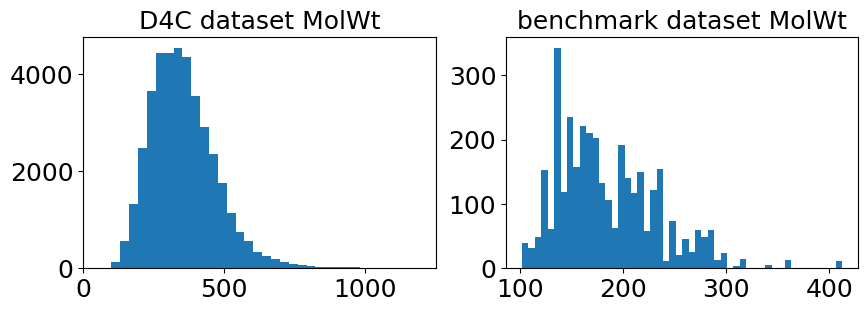

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3))
title = ['D4C dataset MolWt', 'benchmark dataset MolWt']
for i, dataset in enumerate([d4c, benchmark]):    
    molwt_list = [Descriptors.MolWt(Chem.MolFromSmiles(smiles)) for smiles in pd.Series(dataset['Smiles'])]
    if i==0: 
        bin_n = 100
    else:
        bin_n = 50
    axs[i%2].hist(molwt_list, bins=bin_n)
    axs[i%2].set_title(title[i], fontsize=18)
    axs[i%2].tick_params(axis='x', labelsize=18)
    axs[i%2].tick_params(axis = 'y', labelsize=18)
    if i==0:
        axs[i%2].set_xlim(0,1250)
plt.show()

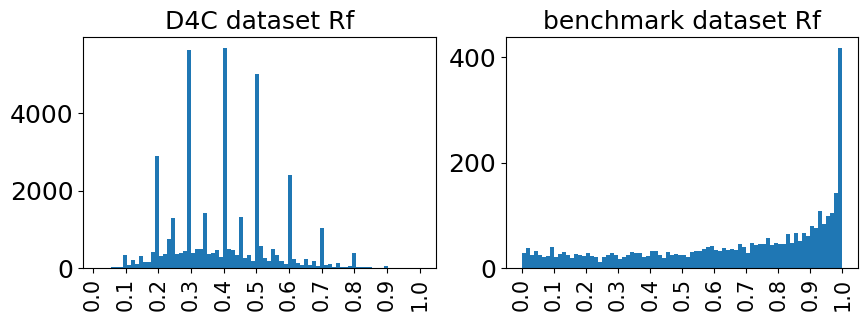

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3))
title = ['D4C dataset Rf', 'benchmark dataset Rf']
bin_n = 80
for i, dataset in enumerate([d4c, benchmark]):    

    axs[i%2].hist(dataset['Rf'], bins=bin_n)
    axs[i%2].set_title(title[i], fontsize=18)
    axs[i%2].set_xticks(np.linspace(0,1,11))
    axs[i%2].tick_params(axis='x', labelsize=15, rotation =90 )
    axs[i%2].tick_params(axis = 'y', labelsize=18)

plt.show()

/tmp/ipykernel_3391524/1842744870.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i%2].set_xticklabels(bi_sys, rotation=45, ha='right')
/tmp/ipykernel_3391524/1842744870.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i%2].set_xticklabels(bi_sys, rotation=45, ha='right')


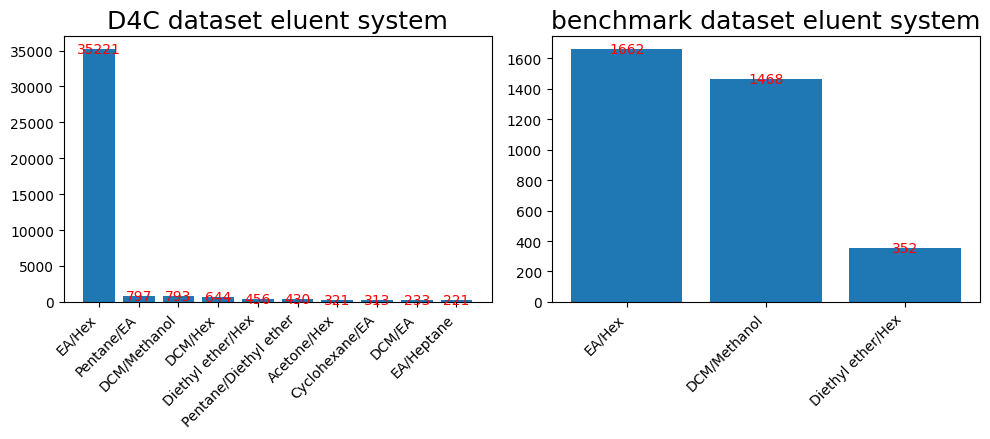

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))

elu_inform = pd.read_csv('./DB/data_process/eluent_standard.csv')
smiles2name_converter = dict(zip(elu_inform['hex_Smiles'], elu_inform['std_name']))

title = ['D4C dataset eluent system', 'benchmark dataset eluent system']
for i, dataset in enumerate([d4c, benchmark]):  
    elu_combi = [set([str(smiles2name_converter[dataset.iloc[i,1]]),str(smiles2name_converter[dataset.iloc[i,2]])]) for i in range(len(dataset))]
    elu_combi = [e.discard('nan') if 'nan' in e else e for e in elu_combi]
    elu_combi_count = pd.Series(elu_combi).value_counts()
    elu_combi_count = elu_combi_count[elu_combi_count>150]
    bi_sys = ['/'.join([list(sys)[0], list(sys)[1]]) for sys in elu_combi_count.index]

    axs[i%2].bar(bi_sys, elu_combi_count)
    axs[i%2].set_title(title[i], fontsize=18)
    axs[i%2].set_xticklabels(bi_sys, rotation=45, ha='right')
    for ii, v in enumerate(elu_combi_count):
        axs[i%2].text(ii, v, str(v), ha='center', va='center', fontsize=10, color = 'red')

plt.tight_layout()
plt.show()


/tmp/ipykernel_3391524/1983762268.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i%2].set_xticklabels(bi_sys, rotation=45, ha='right')
/tmp/ipykernel_3391524/1983762268.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i%2].set_xticklabels(bi_sys, rotation=45, ha='right')


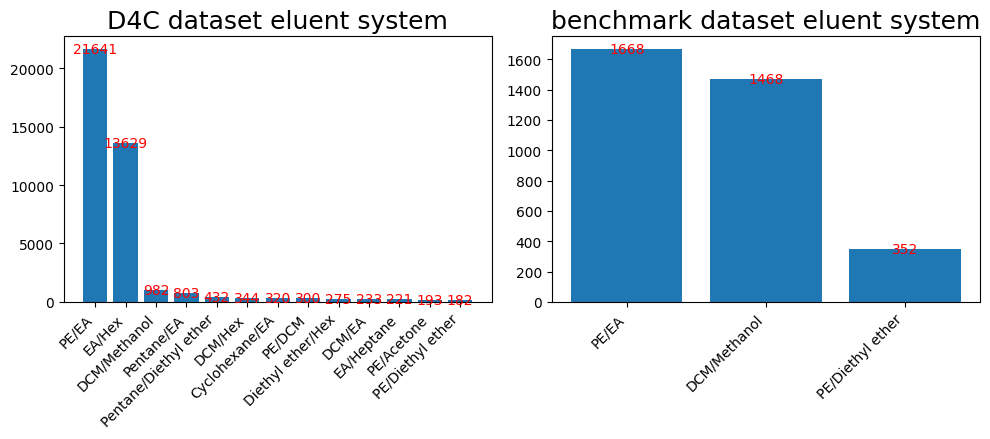

In [ ]:
united_567 = pd.read_csv('./DB/collecting/filtered_data/united_567filtered.csv')
d4c_567 = united_567[united_567['DataSource'] == 'D4C']
benchmark_567 = united_567[united_567['DataSource'] == 'benchmark']

fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))

elu_inform = pd.read_csv('./DB/data_process/eluent_standard.csv')
smiles2name_converter = dict(zip(elu_inform['567_Smiles'], elu_inform['std_name']))

title = ['D4C dataset eluent system', 'benchmark dataset eluent system']
for i, dataset in enumerate([d4c_567, benchmark_567]):  
    elu_combi = [set([str(smiles2name_converter[dataset.iloc[i,1]]),str(smiles2name_converter[dataset.iloc[i,2]])]) for i in range(len(dataset))]
    elu_combi = [e.discard('nan') if 'nan' in e else e for e in elu_combi]
    elu_combi_count = pd.Series(elu_combi).value_counts()
    elu_combi_count = elu_combi_count[elu_combi_count>150]
    bi_sys = ['/'.join([list(sys)[0], list(sys)[1]]) for sys in elu_combi_count.index]

    axs[i%2].bar(bi_sys, elu_combi_count)
    axs[i%2].set_title(title[i], fontsize=18)
    axs[i%2].set_xticklabels(bi_sys, rotation=45, ha='right')
    for ii, v in enumerate(elu_combi_count):
        axs[i%2].text(ii, v, str(v), ha='center', va='center', fontsize=10, color = 'red')

plt.tight_layout()
plt.show()

In [8]:
united

,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,Rf_type,DataSource,doi
0,Br/C(=C\C1SCCCS1)c1ccccc1,CCCCCC,CCOC(C)=O,0.937438,0.062562,0.580000,C,D4C,average of several papers
1,Br/C(=C\n1cc(-c2ccccc2)nn1)c1ccccc1,CCCCCC,CCOC(C)=O,0.789299,0.210701,0.600000,Q,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.4...
2,BrC#Cc1ccc(-n2c3ccccc3c3ccccc32)cc1,CCCCCC,CCOC(C)=O,0.882244,0.117756,0.300000,Q,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...
3,BrC#Cc1ccc(C#Cc2ccccc2)cc1,CCCCCC,CCOC(C)=O,0.937438,0.062562,0.400000,Q,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...
4,BrC#Cc1ccc2c(c1)CC2,CCCCCC,CCOC(C)=O,0.986828,0.013172,0.700000,Q,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...
...,...,...,...,...,...,...,...,...,...
43703,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.863674,0.136326,0.103807,C,benchmark,exp (benchmark
43704,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.926851,0.073149,0.077242,C,benchmark,exp (benchmark
43705,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.950015,0.049985,0.040824,C,benchmark,exp (benchmark
43706,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.969397,0.030603,0.045959,C,benchmark,exp (benchmark


## 사용할 데이터만 추리기

In [9]:
from decimal import Decimal

def is_it_quantized(num):
    a = Decimal(str(num)) % Decimal("0.05") # 문자를 Decimal로 변환시킨 수를 사용해야 부동소수점 오차 안남.
    if a > 0:
        return False
    else:
        return True

def data_scoop(data_df):
    data_df_ = data_df.copy()
    print("C_paper (or data) / Q_data (or data) / D4C / benchmark / all 중 선택")
    w= input("C_paper (or data) / Q_data (or data) / D4C / benchmark / all 중 선택")
    if w == 'C_paper':
        s_data = data_df_[data_df_['Rf_type']=='C']
    elif w == 'C_data':
        q_mask = data_df_['Rf'].apply(is_it_quantized)
        s_data = data_df[~q_mask]

    elif w == 'Q_paper':
        s_data = data_df_[data_df_['Rf_type']=='Q']
    elif w == 'Q_data':
        s_data = data_df_[q_mask]

    elif w == 'D4C':
        s_data = data_df_[data_df_['DataSource'] =='D4C']
    elif w == 'benchmark':
        s_data = data_df_[data_df_['DataSource'] =='benchmark']

    elif w == 'all':
        s_data = data_df_
    else:
        print('뭐 쓸건지 제대로 고르시오! 잘못 골랐거나 안골랐음!')
        return 
    print(f'{w} 골랐음!')
    return s_data

In [10]:
'''united_ = data_scoop(united)
united_.reset_index(drop=True, inplace=True)
united_'''

united_ = data_scoop(united)
# test_data = data_scoop(united)

united_.reset_index(drop=True, inplace=True)
# test_data.reset_index(drop=True, inplace=True)

C_paper (or data) / Q_data (or data) / D4C / benchmark / all 중 선택
C_paper 골랐음!


# mean, variance update

In [ ]:
"""#역sigmoid 라벨 사용
united_E = united_[united_['Rf']<1]
united_E.reset_index(drop=True, inplace=True)
united_E['Rf'] =  -np.log((1/united_E['Rf']) - 1)"""


/tmp/ipykernel_623054/1517872110.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  united_E['Rf'] =  -np.log((1/united_E['Rf']) - 1)


In [ ]:
"""united_ = united_E"""

In [11]:
united_

,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,Rf_type,DataSource,doi
0,Br/C(=C\C1SCCCS1)c1ccccc1,CCCCCC,CCOC(C)=O,0.937438,0.062562,0.580000,C,D4C,average of several papers
1,BrC(Br)=Cn1c2ccccc2c2ccccc21,CCCCC,CCOC(C)=O,0.884089,0.115911,0.900000,C,D4C,average of several papers
2,BrC/C=C\COC1CCCCO1,CCCCCC,CCOCC,0.650419,0.349581,0.690000,C,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.4...
3,BrC1=C(Br)C(c2ccccc2)OC1,CCCCCC,CCOC(C)=O,0.749803,0.250197,0.780000,C,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...
4,BrC1=C[SH](c2ccccc2)C=N1,CCCCCC,CCOC(C)=O,0.870849,0.129151,0.450000,C,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.5...
...,...,...,...,...,...,...,...,...,...
14706,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.863674,0.136326,0.103807,C,benchmark,exp (benchmark
14707,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.926851,0.073149,0.077242,C,benchmark,exp (benchmark
14708,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.950015,0.049985,0.040824,C,benchmark,exp (benchmark
14709,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.969397,0.030603,0.045959,C,benchmark,exp (benchmark


In [4]:
# 여기선 평균, 표준편차만 저장하고 표준화는 graph만들면서 진행

def standardization(DB_df, columns_list, backup=False):
    # columns_list : list of prop

    mean = DB_df[columns_list].mean(axis=0)
    std = DB_df[columns_list].std(axis=0)
    if backup==True:
        np.save('standardization/backup/mean_backup.npy', np.array(mean, dtype = np.float32))
        np.save('standardization/backup/std_backup.npy', np.array(std, dtype = np.float32))
    else:
        np.save('standardization/mean.npy', np.array(mean, dtype = np.float32))
        np.save('standardization/std.npy', np.array(std, dtype = np.float32))
        
    return None


def inverse_standardization(pred_nd_array, mean, std):
    return pred_nd_array * std + mean


In [14]:
# 라벨의 평균, 분산 업데이트

standardization(united_, ['Rf'])

In [ ]:
'''# 라벨의 평균, 분산 backup 저장

standardization(united, ['Rf'], backup=True)'''

# Train/Valid split

In [ ]:
# mol 상관 없이 data point 기준으로 랜덤split
'''
from sklearn.model_selection import train_test_split

train_set, valid_set = train_test_split(united_, test_size=0.2, random_state=42, shuffle=True)
train_set = train_set.reset_index(drop=True)
valid_set = valid_set.reset_index(drop=True)

path_raw = './DB/Rf'
train_set.to_csv(path_raw + '/only_nat_train_randomsplit.csv', index=False)
valid_set.to_csv(path_raw + '/only_nat_valid_randomsplit.csv', index=False)

'''

"\nfrom sklearn.model_selection import train_test_split\n\ntrain_set, valid_set = train_test_split(united, test_size=0.2, random_state=42, shuffle=True)\ntrain_set = train_set.reset_index(drop=True)\nvalid_set = valid_set.reset_index(drop=True)\n\npath_raw = './DB/Rf'\ntrain_set.to_csv(path_raw + '/only_nat_train_randomsplit.csv', index=False)\nvalid_set.to_csv(path_raw + '/only_nat_valid_randomsplit.csv', index=False)\n\n"

In [13]:
# split 하기 전에, 나중에 학습 후 datapoint별 추적을 의한 sample_id 지정해두기
united_.loc[:,'sample_id'] = united_.index

d4c = united_[united_['DataSource'] == 'D4C']
benchmark = united_[united_['DataSource'] == 'benchmark']
print(f'd4c: {len(d4c)}개, benchmark: {len(benchmark)}개')

d4c: 11229개, benchmark: 3482개


In [13]:
def make_test_set_split_only_by_mol(data, test_ratio, random_state=42):

    mol_class = data["Smiles"].drop_duplicates()
    mol_train = mol_class.sample(frac=(1 - test_ratio), random_state=random_state)
    mol_test = mol_class.drop(index=mol_train.index)

    # 3. isin()으로 필터링 - concat 반복 제거
    train_set = data[data["Smiles"].isin(mol_train)].copy()
    test_set = data[data["Smiles"].isin(mol_test)].copy()
    
    # 4. 인덱스 정리
    train_set.reset_index(drop=True, inplace=True)
    test_set.reset_index(drop=True, inplace=True)

    return train_set, test_set


In [14]:

# d4c, nat data 에서 일정 비율로 train/valid 나눠서 일정 비율로 train/valid 구성

train_set1, valid_set1 = make_test_set_split_only_by_mol(d4c, 0.2)
valid_set1, test_set1 = make_test_set_split_only_by_mol(valid_set1, 0.5)

train_set2, valid_set2 = make_test_set_split_only_by_mol(benchmark, 0.2)
valid_set2, test_set2 = make_test_set_split_only_by_mol(valid_set2, 0.5)

train_set = pd.concat([train_set1, train_set2], axis=0).reset_index(drop=True)
valid_set = pd.concat([valid_set1, valid_set2], axis=0).reset_index(drop=True)
test_set = pd.concat([test_set1, test_set2], axis=0).reset_index(drop=True)


In [ ]:
'''
# d4c, nat data 에서 일정 비율로 train/valid 나눠서 일정 비율로 train/valid 구성
# + D4c dataset 에서는 Q_paper data 만 추려서 valid set으로 넘김 (Q 가 오차 있는 데이터라면, 학습땐 손실함수 개선해서 사용하더라도, 검증에서는 빼줘야함)

print(f"d4c 내의 C_paper data 수 : {len(d4c[d4c['Rf_type']=='C'])}")
C_d4c = d4c[d4c['Rf_type']=='C']
Q_d4c = d4c[d4c['Rf_type']!='C']
C_d4c_train_set, C_d4c_valid_set = make_test_set_split_only_by_mol(C_d4c, 0.2)
benchmark_train_set, benchmark_valid_set = make_test_set_split_only_by_mol(benchmark, 0.2)

train_set = pd.concat([C_d4c_train_set, Q_d4c, benchmark_train_set], axis=0).reset_index(drop=True)
valid_set = pd.concat([C_d4c_valid_set, benchmark_valid_set], axis=0).reset_index(drop=True)
'''

'\n# d4c, nat data 에서 일정 비율로 train/valid 나눠서 일정 비율로 train/valid 구성\n# + D4c dataset 에서는 Q_paper data 만 추려서 valid set으로 넘김 (Q 가 오차 있는 데이터라면, 학습땐 손실함수 개선해서 사용하더라도, 검증에서는 빼줘야함)\n\nprint(f"d4c 내의 C_paper data 수 : {len(d4c[d4c[\'Rf_type\']==\'C\'])}")\nC_d4c = d4c[d4c[\'Rf_type\']==\'C\']\nQ_d4c = d4c[d4c[\'Rf_type\']!=\'C\']\nC_d4c_train_set, C_d4c_valid_set = make_test_set_split_only_by_mol(C_d4c, 0.2)\nbenchmark_train_set, benchmark_valid_set = make_test_set_split_only_by_mol(benchmark, 0.2)\n\ntrain_set = pd.concat([C_d4c_train_set, Q_d4c, benchmark_train_set], axis=0).reset_index(drop=True)\nvalid_set = pd.concat([C_d4c_valid_set, benchmark_valid_set], axis=0).reset_index(drop=True)\n'

In [ ]:
path_raw = './DB/Rf'
train_set.to_csv(path_raw + '/United_DB_train.csv', index=False)
valid_set.to_csv(path_raw + '/United_DB_valid.csv', index=False)
test_set.to_csv(path_raw + '/United_DB_test.csv', index=False)

In [5]:
path_raw = './DB/Rf'
train_set = pd.read_csv(path_raw + '/United_DB_train.csv')
valid_set = pd.read_csv(path_raw + '/United_DB_valid.csv')
test_set = pd.read_csv(path_raw + '/United_DB_test.csv')
print(f'trainset: {len(train_set)}개 / validset: {len(valid_set)}개 / testset: {len(test_set)}개')

trainset: 11797개 / validset: 1440개 / testset: 1474개


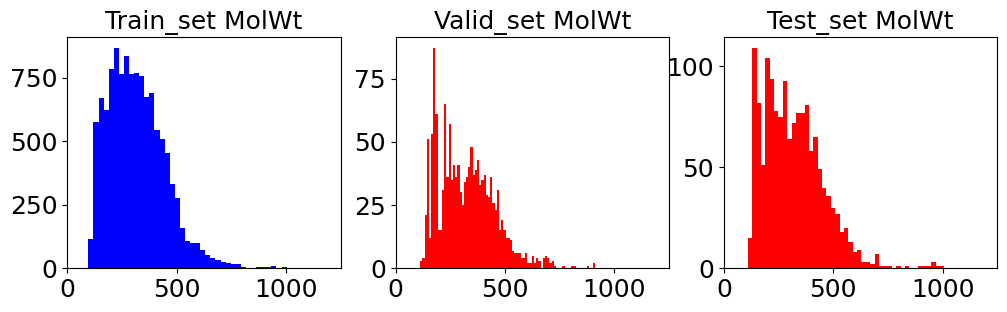

In [13]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
title = ['Train_set MolWt', 'Valid_set MolWt', 'Test_set MolWt']
bin_n = 80
for i, dataset in enumerate([train_set, valid_set, test_set]):    
    if i ==0:
        color = 'blue'
    elif i ==1:
        color = 'red'
    molwt_list = [Descriptors.MolWt(Chem.MolFromSmiles(smiles)) for smiles in pd.Series(dataset['Smiles'])]
    axs[i%3].hist(molwt_list, bins=bin_n, color = color)
    axs[i%3].set_title(title[i], fontsize=18)
    axs[i%3].tick_params(axis='x', labelsize=18)
    axs[i%3].tick_params(axis = 'y', labelsize=18)
    axs[i%3].set_xlim(0,1250)
plt.show()

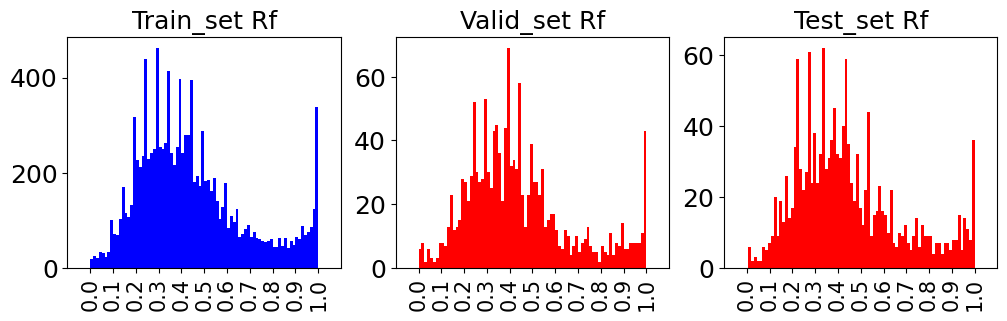

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
title = ['Train_set Rf', 'Valid_set Rf', 'Test_set Rf']
for i, dataset in enumerate([train_set, valid_set, test_set]):    
    if i ==0:
        color = 'blue'
    elif i ==1:
        color = 'red'
    axs[i%3].hist(dataset['Rf'], bins=80, color = color)
    axs[i%3].set_title(title[i], fontsize=18)
    axs[i%3].tick_params(axis='x', labelsize=15, rotation =90 )
    axs[i%3].tick_params(axis = 'y', labelsize=18)

    # axs[i%3].set_xlim(-0.1,1.1)
    # axs[i%3].set_xticks(np.linspace(0,1,11)) 

    axs[i%3].set_xlim(-0.1,1.1)
    axs[i%3].set_xticks(np.linspace(0,1,11))

plt.show()

/tmp/ipykernel_3391524/3030956997.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i%3].set_xticklabels(bi_sys, rotation=45, ha='right')
/tmp/ipykernel_3391524/3030956997.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i%3].set_xticklabels(bi_sys, rotation=45, ha='right')
/tmp/ipykernel_3391524/3030956997.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i%3].set_xticklabels(bi_sys, rotation=45, ha='right')


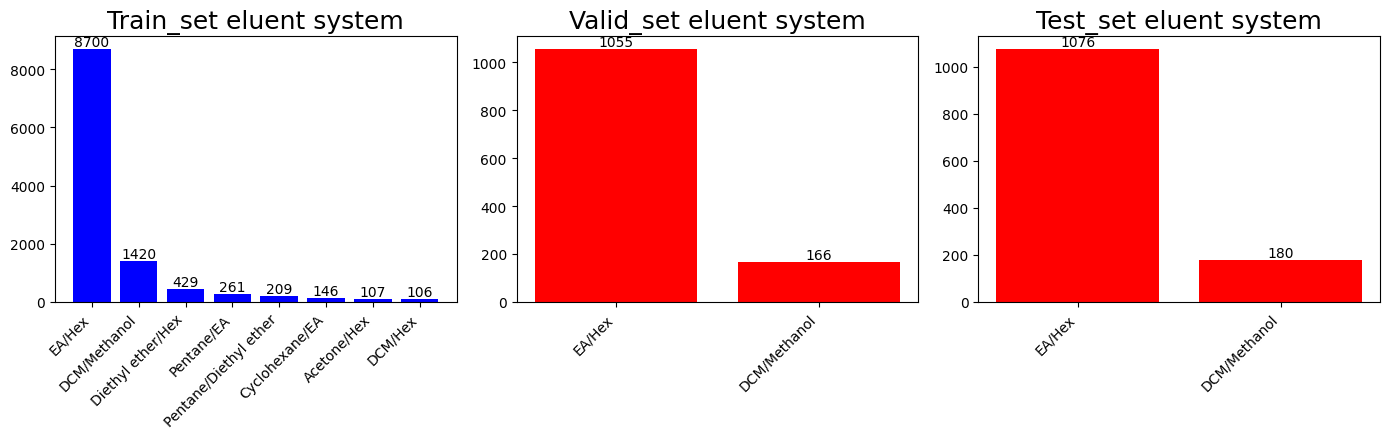

In [ ]:
elu_inform = pd.read_csv('./DB/data_process/eluent_standard.csv')
smiles2name_converter = dict(zip(elu_inform['hex_Smiles'], elu_inform['std_name']))

fig, axs = plt.subplots(1, 3, figsize=(14, 4.5))

title = ['Train_set eluent system', 'Valid_set eluent system', 'Test_set eluent system']
for i, dataset in enumerate([train_set, valid_set, test_set]):  
    if i ==0:
        color = 'blue'
    elif i ==1:
        color = 'red'
    elu_combi = [set([str(smiles2name_converter[dataset.iloc[i,1]]),str(smiles2name_converter[dataset.iloc[i,2]])]) for i in range(len(dataset))]
    elu_combi = [a.discard('nan') if 'nan' in e else e for e in elu_combi]
    elu_combi_count = pd.Series(elu_combi).value_counts()
    elu_combi_count = elu_combi_count[elu_combi_count>100]
    bi_sys = ['/'.join([list(sys)[0], list(sys)[1]]) for sys in elu_combi_count.index]

    axs[i%3].bar(bi_sys, elu_combi_count, color = color)
    axs[i%3].set_title(title[i], fontsize=18)
    axs[i%3].set_xticklabels(bi_sys, rotation=45, ha='right')
    for ii, v in enumerate(elu_combi_count):
        axs[i%3].text(ii, v, str(v), ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

## Make input vector

In [6]:
train_set

,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,Rf_type,DataSource,doi,sample_id
0,Br/C(=C\C1SCCCS1)c1ccccc1,CCCCCC,CCOC(C)=O,0.937438,0.062562,0.580000,C,D4C,average of several papers,0
1,BrC/C=C\COC1CCCCO1,CCCCCC,CCOCC,0.650419,0.349581,0.690000,C,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.4...,2
2,BrC1=C(Br)C(c2ccccc2)OC1,CCCCCC,CCOC(C)=O,0.749803,0.250197,0.780000,C,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...,3
3,BrCCCCCCNc1ccccc1,CCCCCC,CCOC(C)=O,0.789299,0.210701,0.480000,C,D4C,average of several papers,6
4,BrCCc1cccc2ccccc12,CCCCCC,CCOC(C)=O,0.882244,0.117756,0.630000,C,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...,7
...,...,...,...,...,...,...,...,...,...,...
11792,c1ccc(-c2ccccn2)nc1,ClCCl,CO,0.984461,0.015539,0.052081,C,benchmark,exp (benchmark,14696
11793,c1ccc(CNCc2ccccc2)cc1,CCCCCC,CCOCC,0.443636,0.556364,0.280306,C,benchmark,exp (benchmark,14697
11794,c1ccc(CNCc2ccccc2)cc1,CCCCCC,CCOCC,0.614610,0.385390,0.185208,C,benchmark,exp (benchmark,14698
11795,c1ccc2[nH]ccc2c1,CCCCCC,CCOCC,0.443636,0.556364,0.764446,C,benchmark,exp (benchmark,14699


In [7]:
from tqdm.notebook import tqdm
from rdkit.Chem import Descriptors
from rdkit.Chem import rdMolDescriptors
from rdkit.Chem import MACCSkeys
from rdkit.Chem import rdFingerprintGenerator
from rdkit import Chem
from mordred import Calculator, descriptors


def make_compound_representation(set_name):

    #set_name : train_set or valid_Set
    
    #calc = Calculator(descriptors, ignore_3D=True)
    compound_representation=[]
    mgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
    for i in tqdm(range(len(set_name))):
        smiles = set_name['Smiles'][i]
        mol = Chem.MolFromSmiles(smiles)
        # result = calc(mol)
        #Finger = MACCSkeys.GenMACCSKeys(mol) # maccskeys 사용
        Finger = mgen.GetCountFingerprint(mol) # ECFP (Morgan fingerprint) 사용, # Count 기반 (bit 말고)
        sub_data = [x for x in Finger]
        MolWt = Descriptors.ExactMolWt(mol)
        nRotB = Descriptors.NumRotatableBonds(mol)      # Number of rotable bonds
        HBD = Descriptors.NumHDonors(mol)               # Number of H bond donors
        HBA = Descriptors.NumHAcceptors(mol)            # Number of H bond acceptors
        LogP = Descriptors.MolLogP(mol)                 # LogP
        # f6 = result["AATS1s"]
        # f7 = result["ATSC0m"]
        # f8 = result["AXp-2dv"]
        # f9 = result["AXp-3dv"]
        # f10 =result["AETA_eta_FL"]
        # f11 =result["AMID_N"]
        # f12 =result["AATSC0p"]
        f13 = rdMolDescriptors.CalcTPSA(mol)
        # f14 =result["ETA_dEpsilon_D"]
        # f15 =result["PEOE_VSA6"]
        
        sub_data.extend([MolWt,  nRotB, HBD, HBA, LogP, f13])# f6, f7, f8, f9, f10, f11, f12, f14, f15])
        compound_representation.append(sub_data)
    compound_representation = np.vstack(compound_representation)
    return compound_representation

def make_eluent_representation(set_name, elu_column_name, ratio_column_name, ratio_weight=False):

    #elu_column_name : elu1_smiles or elu2_smiles
    
    #eluent representation
    elu_representation=[]
    mgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
    for i in tqdm(range(len(set_name))):
        smiles = set_name[elu_column_name][i]
        if pd.isna(smiles):
            sub_data = list(np.zeros((7,)))
        else:
            mol = Chem.MolFromSmiles(smiles)
            #Finger = MACCSkeys.GenMACCSKeys(mol) # maccskeys 사용
            Finger = mgen.GetCountFingerprint(mol) # ECFP (Morgan fingerprint) 사용 # Count 기반 (bit 말고)
            sub_data = [x for x in Finger]
            MolWt = Descriptors.ExactMolWt(mol)
            nRotB = Descriptors.NumRotatableBonds(mol)      # Number of rotable bonds
            HBD = Descriptors.NumHDonors(mol)               # Number of H bond donors
            HBA = Descriptors.NumHAcceptors(mol)            # Number of H bond acceptors
            LogP = Descriptors.MolLogP(mol)                 # LogP
            f13 = rdMolDescriptors.CalcTPSA(mol) 
            sub_data.extend([MolWt,  nRotB, HBD, HBA, LogP, f13])

            if ratio_weight == True:
                ratio = set_name[ratio_column_name][i]
                sub_data = ratio * np.array(sub_data)
            
        elu_representation.append(sub_data)
    elu_representation = np.vstack(elu_representation)
    return elu_representation

def compound_mixed_eluent_vector(set_name, elu1_column_name, ratio1_column_name, elu2_column_name, ratio2_column_name):

    compound_representation = make_compound_representation(set_name)
    elu1_representation = make_eluent_representation(set_name, elu1_column_name, ratio1_column_name, ratio_weight=True)
    elu2_representation = make_eluent_representation(set_name, elu2_column_name, ratio2_column_name, ratio_weight=True)
    mixed_representation = elu1_representation + elu2_representation

    final_representation = np.hstack([compound_representation, mixed_representation])

    return final_representation

    
def seperate_interact_vector(set_name, elu1_column_name, ratio1_column_name, elu2_column_name, ratio2_column_name, _3body=False):
    compound_representation = make_compound_representation(set_name)
    elu1_representation = make_eluent_representation(set_name, elu1_column_name, ratio1_column_name)
    elu2_representation = make_eluent_representation(set_name, elu2_column_name, ratio2_column_name)

    interact1_representation = np.hstack([compound_representation, elu1_representation])
    interact2_representation = np.hstack([compound_representation, elu2_representation])
    if _3body==True:
        elu_interact_representation = np.hstack([elu1_representation, elu2_representation])

        return interact1_representation, interact2_representation, elu_interact_representation
        
    return interact1_representation, interact2_representation


In [8]:
# <BLI>

# train_input = compound_mixed_eluent_vector(train_set, 'elu1_smiles', 'ratio1', 'elu2_smiles', 'ratio2')
# valid_input = compound_mixed_eluent_vector(valid_set, 'elu1_smiles', 'ratio1', 'elu2_smiles', 'ratio2')
# test_input = compound_mixed_eluent_vector(test_set, 'elu1_smiles', 'ratio1', 'elu2_smiles', 'ratio2')

#=====================================

# <CLI>

# train_input1, train_input2 = seperate_interact_vector(train_set, 'elu1_smiles', 'ratio1', 'elu2_smiles', 'ratio2')
# valid_input1, valid_input2 = seperate_interact_vector(valid_set, 'elu1_smiles', 'ratio1', 'elu2_smiles', 'ratio2')
# test_input1, test_input2 = seperate_interact_vector(test_set, 'elu1_smiles', 'ratio1', 'elu2_smiles', 'ratio2')

#=====================================

# <CLI_3body>

train_input1, train_input2, train_input3 = seperate_interact_vector(train_set, 'elu1_smiles', 'ratio1', 'elu2_smiles', 'ratio2', _3body=True)
valid_input1, valid_input2, valid_input3 = seperate_interact_vector(valid_set, 'elu1_smiles', 'ratio1', 'elu2_smiles', 'ratio2', _3body=True)
test_input1, test_input2, test_input3 = seperate_interact_vector(test_set, 'elu1_smiles', 'ratio1', 'elu2_smiles', 'ratio2', _3body=True)

  0%|          | 0/11797 [00:00<?, ?it/s]

  0%|          | 0/11797 [00:00<?, ?it/s]

  0%|          | 0/11797 [00:00<?, ?it/s]

  0%|          | 0/1440 [00:00<?, ?it/s]

  0%|          | 0/1440 [00:00<?, ?it/s]

  0%|          | 0/1440 [00:00<?, ?it/s]

  0%|          | 0/1474 [00:00<?, ?it/s]

  0%|          | 0/1474 [00:00<?, ?it/s]

  0%|          | 0/1474 [00:00<?, ?it/s]

In [9]:
# <MinMaxScaler (BLI)>

# scaler = MinMaxScaler()
# scaler.fit(train_input)

# train_input = scaler.transform(train_input)
# valid_input = scaler.transform(valid_input)
# test_input = scaler.transform(test_input)


#==========================================================================


# <MinMaxScaler (CLI)>

# scaler = MinMaxScaler()
# scaler.fit(np.hstack([train_input1, train_input2]))

# train_input_full = scaler.transform(np.hstack([train_input1, train_input2]))
# valid_input_full = scaler.transform(np.hstack([valid_input1, valid_input2]))
# test_input_full = scaler.transform(np.hstack([test_input1, test_input2]))

# length = 2*(2048+6)
# train_input1 = train_input_full[:,:length]
# train_input2 = train_input_full[:,length:]
# valid_input1 = valid_input_full[:,:length]
# valid_input2 = valid_input_full[:,length:]
# test_input1 = test_input_full[:,:length]
# test_input2 = test_input_full[:,length:]

#==========================================================================


# <MinMaxScaler (CLI_3body)>

scaler = MinMaxScaler()
scaler.fit(np.hstack([train_input1, train_input2, train_input3]))

train_input_full = scaler.transform(np.hstack([train_input1, train_input2, train_input3]))
valid_input_full = scaler.transform(np.hstack([valid_input1, valid_input2, valid_input3]))
test_input_full = scaler.transform(np.hstack([test_input1, test_input2, test_input3]))

length = 2*(2048+6)
train_input1 = train_input_full[:,:length]
train_input2 = train_input_full[:,length:2*length]
train_input3 = train_input_full[:,2*length:]
valid_input1 = valid_input_full[:,:length]
valid_input2 = valid_input_full[:,length:2*length]
valid_input3 = valid_input_full[:,2*length:]
test_input1 = test_input_full[:,:length]
test_input2 = test_input_full[:,length:2*length]
test_input3 = test_input_full[:,2*length:]

In [10]:
# label
mean = np.load('standardization/mean.npy')
std = np.load('standardization/std.npy')

train_label = (np.array(train_set['Rf']).reshape(-1,1)-mean)/std
valid_label = (np.array(valid_set['Rf']).reshape(-1,1)-mean)/std
test_label = (np.array(test_set['Rf']).reshape(-1,1)-mean)/std

## dataloader
#### batch_size는 흔히 하는 그 batch의 크기 : 데이터 샘플의 개수

In [ ]:
"""# BLI용 Dataloader

train_dataset = TensorDataset(torch.tensor(train_input, dtype=torch.float32), torch.tensor(train_label, dtype=torch.float32), torch.tensor(train_set['sample_id'].values, dtype=torch.long))
valid_dataset = TensorDataset(torch.tensor(valid_input, dtype=torch.float32), torch.tensor(valid_label, dtype=torch.float32), torch.tensor(valid_set['sample_id'].values, dtype=torch.long))
test_dataset = TensorDataset(torch.tensor(test_input, dtype=torch.float32), torch.tensor(test_label, dtype=torch.float32), torch.tensor(test_set['sample_id'].values, dtype=torch.long))

train_loader = DataLoader(train_dataset, batch_size=500, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=500, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=500, shuffle=True)"""

In [20]:
# CLI용 Dataloader

train_dataset = TensorDataset(
    torch.tensor(train_input1, dtype=torch.float32), torch.tensor(train_input2, dtype=torch.float32),                             # interaction1, 2
    torch.tensor(train_label, dtype=torch.float32),                                                                               # label
    torch.tensor(train_set['ratio1'].values.reshape(-1,1)), torch.tensor(train_set['ratio2'].values.reshape(-1,1)),               # ratio1, 2 
    torch.tensor(train_set['sample_id'].values, dtype=torch.long)                                                                 # sample id
    )
valid_dataset = TensorDataset(
    torch.tensor(valid_input1, dtype=torch.float32), torch.tensor(valid_input2, dtype=torch.float32), 
    torch.tensor(valid_label, dtype=torch.float32), 
    torch.tensor(valid_set['ratio1'].values.reshape(-1,1)), torch.tensor(valid_set['ratio2'].values.reshape(-1,1)), 
    torch.tensor(valid_set['sample_id'].values, dtype=torch.long)
    )
test_dataset = TensorDataset(
    torch.tensor(test_input1, dtype=torch.float32), torch.tensor(test_input2, dtype=torch.float32), 
    torch.tensor(test_label, dtype=torch.float32), 
    torch.tensor(test_set['ratio1'].values.reshape(-1,1)), torch.tensor(test_set['ratio2'].values.reshape(-1,1)), 
    torch.tensor(test_set['sample_id'].values, dtype=torch.long)
    )

train_loader = DataLoader(train_dataset, batch_size=500, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=500, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=500, shuffle=True)

In [11]:
# CLI_3body용 Dataloader

# interaction1, 2, 3
# label
# ratio1, 2 , 3
# sample id

train_dataset = TensorDataset(
    torch.tensor(train_input1, dtype=torch.float32), torch.tensor(train_input2, dtype=torch.float32), torch.tensor(train_input3, dtype=torch.float32),
    torch.tensor(train_label, dtype=torch.float32),
    torch.tensor(train_set['ratio1'].values.reshape(-1,1)), torch.tensor(train_set['ratio2'].values.reshape(-1,1)), 
    torch.tensor(np.minimum(train_set['ratio1'].values, train_set['ratio2'].values).reshape(-1,1), dtype=torch.float32),
    torch.tensor(train_set['sample_id'].values, dtype=torch.long)
    )
valid_dataset = TensorDataset(
    torch.tensor(valid_input1, dtype=torch.float32), torch.tensor(valid_input2, dtype=torch.float32),  torch.tensor(valid_input3, dtype=torch.float32),
    torch.tensor(valid_label, dtype=torch.float32), 
    torch.tensor(valid_set['ratio1'].values.reshape(-1,1)), torch.tensor(valid_set['ratio2'].values.reshape(-1,1)), 
    torch.tensor(np.minimum(valid_set['ratio1'].values, valid_set['ratio2'].values).reshape(-1,1), dtype=torch.float32),
    torch.tensor(valid_set['sample_id'].values, dtype=torch.long)
    )
test_dataset = TensorDataset(
    torch.tensor(test_input1, dtype=torch.float32), torch.tensor(test_input2, dtype=torch.float32), torch.tensor(test_input3, dtype=torch.float32),
    torch.tensor(test_label, dtype=torch.float32), 
    torch.tensor(test_set['ratio1'].values.reshape(-1,1)), torch.tensor(test_set['ratio2'].values.reshape(-1,1)), 
    torch.tensor(np.minimum(test_set['ratio1'].values, test_set['ratio2'].values).reshape(-1,1), dtype=torch.float32),
    torch.tensor(test_set['sample_id'].values, dtype=torch.long)
    )

train_loader = DataLoader(train_dataset, batch_size=500, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=500, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=500, shuffle=True)

In [12]:
train_iter = iter(train_loader)
a,b,c,d,e,f,g,h = next(train_iter)


## MODEL

In [ ]:
class BLI_ECFP_MLP(torch.nn.Module):
    def __init__(self, input_size, dropout=0.0):
        super().__init__()

        self.dropout=dropout
        self.input_size = input_size

        self.interaction_linear_list = nn.ModuleList([nn.Linear(in_features = self.input_size, out_features = 2048),
                            nn.LeakyReLU(0.1),
                            nn.BatchNorm1d(2048),
                            nn.Dropout(self.dropout),
                            nn.Linear(2048, 1024),
                            nn.LeakyReLU(0.1),
                            nn.BatchNorm1d(1024),
                            nn.Linear(1024, 512),
                            nn.LeakyReLU(0.1),
                            nn.BatchNorm1d(512)])

        
        self.pred_list = nn.ModuleList([nn.Linear(in_features =512 , out_features = 256),
                                        nn.LeakyReLU(0.1),
                                        nn.BatchNorm1d(256),
                                        nn.Linear(256 ,128),
                                        nn.LeakyReLU(0.1),
                                        nn.BatchNorm1d(128),
                                        nn.Linear(128, 1)])


        self.interaction_linear_list.apply(self._init_weights)
        self.pred_list.apply(self._init_weights)
        

    def _init_weights(self, m):
        if isinstance(m , nn.Linear):
            nn.init.xavier_uniform_(m.weight)
            if m.bias is not None:
                nn.init.zeros_(m.bias)

    def forward(self, compound_mixed_elu_descriptor):

        interaction_data = compound_mixed_elu_descriptor
        for layer in self.interaction_linear_list:
            interaction_data = layer(interaction_data)

        retention = interaction_data
        for layer in self.pred_list:
            retention = layer(retention)
            
        return retention

In [21]:
class CLI_ECFP_MLP(torch.nn.Module):
    def __init__(self, input_size, dropout=0.0):
        super().__init__()

        self.dropout=dropout
        self.input_size = input_size

        self.interaction_linear_list = nn.ModuleList([nn.Linear(in_features = self.input_size, out_features = 2048),
                            nn.LeakyReLU(0.1),
                            nn.BatchNorm1d(2048),
                            nn.Dropout(self.dropout),
                            nn.Linear(2048, 1024),
                            nn.LeakyReLU(0.1),
                            nn.BatchNorm1d(1024),
                            nn.Linear(1024, 512),
                            nn.LeakyReLU(0.1),
                            nn.BatchNorm1d(512)])
        
        self.pred_list = nn.ModuleList([nn.Linear(in_features =512 , out_features = 256),
                                        nn.LeakyReLU(0.1),
                                        nn.BatchNorm1d(256),
                                        nn.Linear(256 ,128),
                                        nn.LeakyReLU(0.1),
                                        nn.BatchNorm1d(128),
                                        nn.Linear(128, 1)])


        self.interaction_linear_list.apply(self._init_weights)
        self.pred_list.apply(self._init_weights)
        

    def _init_weights(self, m):
        if isinstance(m , nn.Linear):
            nn.init.xavier_uniform_(m.weight)
            if m.bias is not None:
                nn.init.zeros_(m.bias)

    def forward(self, interaction1, interaction2, ratio1, ratio2):

        interaction_vector1 = interaction1
        interaction_vector2 = interaction2
        for layer in self.interaction_linear_list:
            interaction_vector1 = layer(interaction_vector1)
        for layer in self.interaction_linear_list:
            interaction_vector2 = layer(interaction_vector2)

        ratio1 = ratio1.view(-1, 1).float()
        ratio2 = ratio2.view(-1, 1).float()
        United_interaction = interaction_vector1*ratio1 + interaction_vector2*ratio2

        retention = United_interaction
        for layer in self.pred_list:
            retention = layer(retention)
            
        return retention

In [13]:
class CLI_3body_ECFP_MLP(torch.nn.Module):
    def __init__(self, input_size, dropout=0.0):
        super().__init__()

        self.dropout=dropout
        self.input_size = input_size

        self.interaction_linear_list = nn.ModuleList([nn.Linear(in_features = self.input_size, out_features = 2048),
                            nn.LeakyReLU(0.1),
                            nn.BatchNorm1d(2048),
                            nn.Dropout(self.dropout),
                            nn.Linear(2048, 1024),
                            nn.LeakyReLU(0.1),
                            nn.BatchNorm1d(1024),
                            nn.Linear(1024, 512),
                            nn.LeakyReLU(0.1),
                            nn.BatchNorm1d(512)])
        

        self.elu_interaction_linear_list = nn.ModuleList(
            [
                nn.Linear(in_features=self.input_size, out_features=2048),
                nn.LeakyReLU(0.1),
                nn.BatchNorm1d(2048),
                nn.Dropout(self.dropout),
                nn.Linear(2048, 1024),
                nn.LeakyReLU(0.1),
                nn.BatchNorm1d(1024),               
                nn.Linear(1024, 512),
                nn.LeakyReLU(0.1),
                nn.BatchNorm1d(512),
            ]
        )

        self.pred_list = nn.ModuleList([nn.Linear(in_features =512 , out_features = 256),
                                        nn.LeakyReLU(0.1),
                                        nn.BatchNorm1d(256),
                                        nn.Linear(256 ,128),
                                        nn.LeakyReLU(0.1),
                                        nn.BatchNorm1d(128),
                                        nn.Linear(128, 1)])


        self.interaction_linear_list.apply(self._init_weights)
        self.pred_list.apply(self._init_weights)
        self.elu_interaction_linear_list.apply(self._init_weights)

    def _init_weights(self, m):
        if isinstance(m , nn.Linear):
            nn.init.xavier_uniform_(m.weight)
            if m.bias is not None:
                nn.init.zeros_(m.bias)

    def forward(self, interaction1, interaction2, interaction3, ratio1, ratio2, ratio3):

        interaction_vector1 = interaction1
        interaction_vector2 = interaction2
        interaction_vector3 = interaction3

        for layer in self.interaction_linear_list:
            interaction_vector1 = layer(interaction_vector1)
        for layer in self.interaction_linear_list:
            interaction_vector2 = layer(interaction_vector2)
        for layer in self.elu_interaction_linear_list:
            interaction_vector3 = layer(interaction_vector3)

        ratio1 = ratio1.view(-1, 1).float()
        ratio2 = ratio2.view(-1, 1).float()
        United_interaction = interaction_vector1*ratio1 + interaction_vector2*ratio2 + interaction_vector3*ratio3

        retention = United_interaction
        for layer in self.pred_list:
            retention = layer(retention)
            
        return retention

# Run

In [14]:
# simle one

class CallBack():
    def __init__(self, patience=20, delta=0.0, optimal_path='./ckpt/opt_checkpoint.pt', last_path = './ckpt/last_ckpt.pt'):
        self.patience = patience
        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.delta = delta
        self.opt_path = optimal_path
        self.last_path = last_path

    def __call__(self, epoch, model, optimizer, scheduler, train_loss, train_r2, valid_loss, valid_r2):
        
        # save last checkpoint
        self.save_last_checkpoint(epoch, model, optimizer, scheduler, train_loss, train_r2, valid_loss, valid_r2)

        # save optimal checkpoint
        score = valid_loss[-1]
        if self.best_score is None:
            self.best_score = score
            self.save_optimal_checkpoint(epoch, model, train_loss, train_r2, valid_loss, valid_r2)
        elif score >= self.best_score - self.delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.save_optimal_checkpoint(epoch, model, train_loss, train_r2, valid_loss, valid_r2)
            self.counter = 0

        return self.early_stop

    def save_optimal_checkpoint(self, epoch, model, train_loss, train_r2, valid_loss, valid_r2):

        # 저장 중간에 학습 중단하면 파일 깨져버리기 때문에 임시파일에 저장 먼저 함
        # 저장 중 중단되면 temp_path는 손상되지만, os.replace 과정에서 정상 저장된 파일 까지만 save_path로 교체
        
        temp_path = self.opt_path + '.tmp'  
        torch.save({'epoch' : epoch,
                    'model_state_dict' : model.state_dict(),
                    'train_loss' :train_loss[-1],
                    'train_r2' :train_r2[-1],
                    'valid_loss' : valid_loss[-1],
                    'valid_r2' :valid_r2[-1]},
                  temp_path)
        os.replace(temp_path, self.opt_path)

    def save_last_checkpoint(self, epoch, model, opt, sch, train_loss, train_r2, valid_loss, valid_r2):
        temp_path = self.last_path + '.tmp'
        torch.save({'epoch': epoch,
                   'model_state_dict' : model.state_dict(),
                   'optimizer_state_dict' : opt.state_dict(),
                   'scheduler_state_dict' : sch.state_dict(),
                   'train_loss' : train_loss,
                   'train_r2' :train_r2,
                   'valid_loss' : valid_loss,
                   'valid_r2' :valid_r2},
                  temp_path)
        os.replace(temp_path, self.last_path)

In [15]:
# loss_functions

def custom_mae_loss(output, label, purpose = 'train'):

    output = output[0] if isinstance(output, (tuple, list)) else output
    output = output.reshape(label.shape)
    
    nan_mask = ~torch.isnan(label)
    if purpose == 'train':
        std_mae = torch.mean(torch.abs(output[nan_mask]-label[nan_mask]))
        return std_mae


    elif purpose == 'lookup':
        real_output = inverse_standardization(output, mean, std)
        real_label = inverse_standardization(label, mean, std)
        real_mae = torch.mean(torch.abs(real_output[nan_mask]-real_label[nan_mask]))
        return real_mae


def r2_score(preds, targets):
    nan_mask = ~torch.isnan(targets)
    preds = preds[nan_mask]
    targets = targets[nan_mask]
    mean = targets.mean()
    ss_res = torch.sum((targets - preds) ** 2)
    ss_tot = torch.sum((targets - mean) ** 2)
    return 1 - (ss_res / (ss_tot + 1e-12))

In [ ]:
class Run_BLI_ECFP_MLP():

    def __init__(self, device, relay, model, loss_fn, optimizer, scheduler, callback, log_path, last_ckpt_path, early_stopping=False, total_epoch = 1000):

        # relay : True or False --> True 일 경우 이어서 학습
        self.device = device
        self.relay = relay
        self.model = model
        self.loss_fn = loss_fn
        self.optimizer = optimizer
        self.scheduler = scheduler
        self.callback = callback
        self.log_path = log_path
        self.lask_ckpt_path = lask_ckpt_path
        self.start_epoch = 0
        self.total_epoch = total_epoch
        self.error_log_train= []
        self.r2_log_train=[]
        self.error_log_valid = []
        self.r2_log_valid=[]
        self.early_stopping = early_stopping
        
        if self.relay:
            self.last_ckpt = torch.load(self.last_ckpt_path)
            self.model.load_state_dict(self.last_ckpt['model_state_dict'])
            self.optimizer.load_state_dict(self.last_ckpt['optimizer_state_dict'])
            self.scheduler.load_state_dict(self.last_ckpt['scheduler_state_dict'])
            self.start_epoch = self.last_ckpt['epoch']+1
            self.error_log_train = self.last_ckpt.get('train_loss', [])
            self.r2_log_train = self.last_ckpt.get('train_r2', [])
            self.error_log_valid = self.last_ckpt.get('valid_loss', [])
            self.r2_log_valid = self.last_ckpt.get('valid_r2', [])

            if self.start_epoch >=  self.total_epoch:
                raise ValueError(f'총 epoch: {self.total_epoch}가 이전에 저장된 epoch: {self.start_epoch} 보다 작음')
               
    def __call__(self, train_loader, valid_loader):
        
        for epoch in tqdm(range(self.start_epoch, self.total_epoch)):
            self.model.train()
            train_out_all=[]
            train_label_all=[]
            valid_out_all=[]
            valid_label_all=[]
            for x,y,i in train_loader:
                x_batch = x.to(self.device)
                y_batch = y.to(self.device)
                out = self.model(x_batch)   
                self.optimizer.zero_grad()             
                loss = self.loss_fn(out, y_batch)
                loss.backward()
                self.optimizer.step()
                
                train_out_all.append(out.detach().view(-1))
                train_label_all.append(y_batch.detach().view(-1))
                
            train_out_all = torch.cat(train_out_all, dim=0)
            train_label_all = torch.cat(train_label_all, dim=0)
            train_epoch_MAE = self.loss_fn(train_out_all, train_label_all, purpose = 'lookup')
            self.error_log_train.append(train_epoch_MAE.item())
            train_epoch_r2 = r2_score(train_out_all, train_label_all)
            self.r2_log_train.append(train_epoch_r2.item())
        
            self.model.eval()
            with torch.no_grad():      
                for x,y,i in valid_loader:
                    x_batch = x.to(self.device)
                    y_batch = y.to(self.device)
                    pred = self.model(x_batch)                    
                    valid_out_all.append(pred.detach().view(-1))
                    valid_label_all.append(y_batch.detach().view(-1))
        
            valid_out_all = torch.cat(valid_out_all, dim=0)
            valid_label_all = torch.cat(valid_label_all, dim=0)
            valid_epoch_MAE = self.loss_fn(valid_out_all, valid_label_all, purpose = 'lookup')
            self.error_log_valid.append(valid_epoch_MAE.item())
            valid_epoch_r2 = r2_score(valid_out_all, valid_label_all)
            self.r2_log_valid.append(valid_epoch_r2.item())
        
            # schedular
            self.scheduler.step()
        
            # Early stop & callback
            early_stop = self.callback(epoch, self.model, self.optimizer, self.scheduler, 
                           train_loss = self.error_log_train,
                           train_r2 = self.r2_log_train,
                           valid_loss = self.error_log_valid,
                           valid_r2 = self.r2_log_valid)
                           
        
            print(f'Epoch : {epoch+1} | Train_loss : {self.error_log_train[-1]:.4f}, Train_r2 : {self.r2_log_train[-1]:.4f} | Valid_loss : {self.error_log_valid[-1]:.4f}, Valid_r2 : {self.r2_log_valid[-1]:.4f}')
        
            logging_path = self.log_path + 'train&valid_logging.txt'
            with open(logging_path, 'a') as f:
                f.write(f'Epoch : {epoch+1} | Train_loss : {self.error_log_train[-1]:.4f}, Train_r2 : {self.r2_log_train[-1]:.4f} | Valid_loss : {self.error_log_valid[-1]:.4f}, Valid_r2 : {self.r2_log_valid[-1]:.4f}')

            if early_stop:
                if self.early_stopping == True:
                    print(f'Early stopping at epoch {epoch+1}')
                    break

In [ ]:
class Run_CLI_ECFP_MLP():

    def __init__(self, device, relay, model, loss_fn, optimizer, scheduler, callback, log_path, last_ckpt_path, early_stopping=False, total_epoch = 1000):

        # relay : True or False --> True 일 경우 이어서 학습
        self.device = device
        self.relay = relay
        self.model = model
        self.loss_fn = loss_fn
        self.optimizer = optimizer
        self.scheduler = scheduler
        self.callback = callback
        self.log_path = log_path
        self.last_ckpt_path = last_ckpt_path
        self.start_epoch = 0
        self.total_epoch = total_epoch
        self.error_log_train= []
        self.r2_log_train= []
        self.error_log_valid = []
        self.r2_log_valid= []
        self.early_stopping = early_stopping
        
        if self.relay:
            self.last_ckpt = torch.load(self.last_ckpt_path)
            self.model.load_state_dict(self.last_ckpt['model_state_dict'])
            self.optimizer.load_state_dict(self.last_ckpt['optimizer_state_dict'])
            self.scheduler.load_state_dict(self.last_ckpt['scheduler_state_dict'])
            self.start_epoch = self.last_ckpt['epoch']+1
            self.error_log_train = self.last_ckpt.get('train_loss', [])
            self.r2_log_train = self.last_ckpt.get('train_r2', [])
            self.error_log_valid = self.last_ckpt.get('valid_loss', [])
            self.r2_log_valid = self.last_ckpt.get('valid_r2', [])

            if self.start_epoch >=  self.total_epoch:
                raise ValueError(f'총 epoch: {self.total_epoch}가 이전에 저장된 epoch: {self.start_epoch} 보다 작음')
               
    def __call__(self, train_loader, valid_loader):
        
        for epoch in tqdm(range(self.start_epoch, self.total_epoch)):
            self.model.train()
            train_out_all=[]
            train_label_all=[]
            valid_out_all=[]
            valid_label_all=[]
            for inter1, inter2, label, ratio1, ratio2, i in train_loader:
                inter1_batch = inter1.to(self.device)
                inter2_batch = inter2.to(self.device)
                y_batch = label.to(self.device)
                ratio1_batch = ratio1.to(self.device)
                ratio2_batch = ratio2.to(self.device)
                out = self.model(inter1_batch, inter2_batch, ratio1_batch, ratio2_batch)   
                self.optimizer.zero_grad()             
                loss = self.loss_fn(out, y_batch)
                loss.backward()
                self.optimizer.step()
                
                train_out_all.append(out.detach().view(-1))
                train_label_all.append(y_batch.detach().view(-1))
                
            train_out_all = torch.cat(train_out_all, dim=0)
            train_label_all = torch.cat(train_label_all, dim=0)
            train_epoch_MAE = self.loss_fn(train_out_all, train_label_all, purpose = 'lookup')
            self.error_log_train.append(train_epoch_MAE.item())
            train_epoch_r2 = r2_score(train_out_all, train_label_all)
            self.r2_log_train.append(train_epoch_r2.item())
        
            self.model.eval()
            with torch.no_grad():      
                for inter1, inter2, label, ratio1, ratio2, i in valid_loader:
                    inter1_batch = inter1.to(self.device)
                    inter2_batch = inter2.to(self.device)
                    y_batch = label.to(self.device)
                    ratio1_batch = ratio1.to(self.device)
                    ratio2_batch = ratio2.to(self.device)
                    pred = self.model(inter1_batch, inter2_batch, ratio1_batch, ratio2_batch)                    
                    valid_out_all.append(pred.detach().view(-1))
                    valid_label_all.append(y_batch.detach().view(-1))
        
            valid_out_all = torch.cat(valid_out_all, dim=0)
            valid_label_all = torch.cat(valid_label_all, dim=0)
            valid_epoch_MAE = self.loss_fn(valid_out_all, valid_label_all, purpose = 'lookup')
            self.error_log_valid.append(valid_epoch_MAE.item())
            valid_epoch_r2 = r2_score(valid_out_all, valid_label_all)
            self.r2_log_valid.append(valid_epoch_r2.item())
        
            # schedular
            self.scheduler.step()
        
            # Early stop & callback
            early_stop = self.callback(epoch, self.model, self.optimizer, self.scheduler, 
                           train_loss = self.error_log_train,
                           train_r2 = self.r2_log_train,
                           valid_loss = self.error_log_valid,
                           valid_r2 = self.r2_log_valid)
                           
        
            print(f'Epoch : {epoch+1} | Train_loss : {self.error_log_train[-1]:.4f}, Train_r2 : {self.r2_log_train[-1]:.4f} | Valid_loss : {self.error_log_valid[-1]:.4f}, Valid_r2 : {self.r2_log_valid[-1]:.4f}')
        
            logging_path = self.log_path +'train&valid_logging.txt'
            with open(logging_path, 'a') as f:
                f.write(f'Epoch : {epoch+1} | Train_loss : {self.error_log_train[-1]:.4f}, Train_r2 : {self.r2_log_train[-1]:.4f} | Valid_loss : {self.error_log_valid[-1]:.4f}, Valid_r2 : {self.r2_log_valid[-1]:.4f}')

            if early_stop:
                if self.early_stopping == True:
                    print(f'Early stopping at epoch {epoch+1}')
                    break

In [16]:
class Run_CLI_3body_ECFP_MLP():

    def __init__(self, device, relay, model, loss_fn, optimizer, scheduler, callback, log_path, last_ckpt_path, early_stopping=False, total_epoch = 1000):

        # relay : True or False --> True 일 경우 이어서 학습
        self.device = device
        self.relay = relay
        self.model = model
        self.loss_fn = loss_fn
        self.optimizer = optimizer
        self.scheduler = scheduler
        self.callback = callback
        self.log_path = log_path
        self.last_ckpt_path = last_ckpt_path
        self.start_epoch = 0
        self.total_epoch = total_epoch
        self.error_log_train= []
        self.r2_log_train= []
        self.error_log_valid = []
        self.r2_log_valid= []
        self.early_stopping = early_stopping
        
        if self.relay:
            self.last_ckpt = torch.load(self.last_ckpt_path)
            self.model.load_state_dict(self.last_ckpt['model_state_dict'])
            self.optimizer.load_state_dict(self.last_ckpt['optimizer_state_dict'])
            self.scheduler.load_state_dict(self.last_ckpt['scheduler_state_dict'])
            self.start_epoch = self.last_ckpt['epoch']+1
            self.error_log_train = self.last_ckpt.get('train_loss', [])
            self.r2_log_train = self.last_ckpt.get('train_r2', [])
            self.error_log_valid = self.last_ckpt.get('valid_loss', [])
            self.r2_log_valid = self.last_ckpt.get('valid_r2', [])

            if self.start_epoch >=  self.total_epoch:
                raise ValueError(f'총 epoch: {self.total_epoch}가 이전에 저장된 epoch: {self.start_epoch} 보다 작음')
               
    def __call__(self, train_loader, valid_loader):
        
        for epoch in tqdm(range(self.start_epoch, self.total_epoch)):
            self.model.train()
            train_out_all=[]
            train_label_all=[]
            valid_out_all=[]
            valid_label_all=[]
            for inter1, inter2, inter3, label, ratio1, ratio2, ratio3, i in train_loader:
                inter1_batch = inter1.to(self.device)
                inter2_batch = inter2.to(self.device)
                inter3_batch = inter3.to(self.device)
                y_batch = label.to(self.device)
                ratio1_batch = ratio1.to(self.device)
                ratio2_batch = ratio2.to(self.device)
                ratio3_batch = ratio3.to(self.device)
                out = self.model(inter1_batch, inter2_batch, inter3_batch, ratio1_batch, ratio2_batch, ratio3_batch)   
                self.optimizer.zero_grad()             
                loss = self.loss_fn(out, y_batch)
                loss.backward()
                self.optimizer.step()
                
                train_out_all.append(out.detach().view(-1))
                train_label_all.append(y_batch.detach().view(-1))
                
            train_out_all = torch.cat(train_out_all, dim=0)
            train_label_all = torch.cat(train_label_all, dim=0)
            train_epoch_MAE = self.loss_fn(train_out_all, train_label_all, purpose = 'lookup')
            self.error_log_train.append(train_epoch_MAE.item())
            train_epoch_r2 = r2_score(train_out_all, train_label_all)
            self.r2_log_train.append(train_epoch_r2.item())
        
            self.model.eval()
            with torch.no_grad():      
                for inter1, inter2, inter3, label, ratio1, ratio2, ratio3, i in valid_loader:
                    inter1_batch = inter1.to(self.device)
                    inter2_batch = inter2.to(self.device)
                    inter3_batch = inter3.to(self.device)
                    y_batch = label.to(self.device)
                    ratio1_batch = ratio1.to(self.device)
                    ratio2_batch = ratio2.to(self.device)
                    ratio3_batch = ratio3.to(self.device)
                    pred = self.model(inter1_batch, inter2_batch, inter3_batch, ratio1_batch, ratio2_batch, ratio3_batch)                    
                    valid_out_all.append(pred.detach().view(-1))
                    valid_label_all.append(y_batch.detach().view(-1))
        
            valid_out_all = torch.cat(valid_out_all, dim=0)
            valid_label_all = torch.cat(valid_label_all, dim=0)
            valid_epoch_MAE = self.loss_fn(valid_out_all, valid_label_all, purpose = 'lookup')
            self.error_log_valid.append(valid_epoch_MAE.item())
            valid_epoch_r2 = r2_score(valid_out_all, valid_label_all)
            self.r2_log_valid.append(valid_epoch_r2.item())
        
            # schedular
            self.scheduler.step()
        
            # Early stop & callback
            early_stop = self.callback(epoch, self.model, self.optimizer, self.scheduler, 
                           train_loss = self.error_log_train,
                           train_r2 = self.r2_log_train,
                           valid_loss = self.error_log_valid,
                           valid_r2 = self.r2_log_valid)
                           
        
            print(f'Epoch : {epoch+1} | Train_loss : {self.error_log_train[-1]:.4f}, Train_r2 : {self.r2_log_train[-1]:.4f} | Valid_loss : {self.error_log_valid[-1]:.4f}, Valid_r2 : {self.r2_log_valid[-1]:.4f}')
        
            logging_path = self.log_path +'/train&valid_logging.txt'
            with open(logging_path, 'a') as f:
                f.write(f'Epoch : {epoch+1} | Train_loss : {self.error_log_train[-1]:.4f}, Train_r2 : {self.r2_log_train[-1]:.4f} | Valid_loss : {self.error_log_valid[-1]:.4f}, Valid_r2 : {self.r2_log_valid[-1]:.4f}')

            if early_stop:
                if self.early_stopping == True:
                    print(f'Early stopping at epoch {epoch+1}')
                    break

In [17]:
# simple run


from tqdm.auto import tqdm

path = 'ckpt_paper/ckpt_<C_paper_final>_<tvt>_CLI_3body_ECFP+descriptors_MLP_dropout0.3'
os.makedirs(path, exist_ok=False)
last_ckpt_path =  path + '/last_ckpt.pt'
optimal_ckpt_path = path + '/opt_checkpoint.pt'

read_me_path = path + '/about_this_model.txt'
arc = input('which version of model?')
about_data = input('used data / how to split train_test? (no dup data? or no dup mol?)')
pe = input('how to handle PE?')
pooling = input('how to pool context GCN vector?')
etc = input('anyting else to notice')
with open(read_me_path, 'a') as f:
    f.write(f'Model : {arc}\nAbout data : {about_data}\nPE : {pe}\nPooling : {pooling}\netc : {etc}')


device = torch.device('cuda:2')
model = CLI_3body_ECFP_MLP(input_size = 2*(2048+6), dropout=0.3).to(device)
loss_fn = custom_mae_loss
optimizer = torch.optim.Adam(model.parameters(), lr = 0.001, weight_decay = 5e-4)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size = 50, gamma= 1-0.015)
callback = CallBack(patience = 300, optimal_path = optimal_ckpt_path, last_path = last_ckpt_path)

# loss normalize
mean = torch.tensor(np.load('standardization/mean.npy')).to(device)
std = torch.tensor(np.load('standardization/std.npy')).to(device)



# class : run model
# from Run_model import Run_deep_Rf
model_deep_Rf = Run_CLI_3body_ECFP_MLP(device=device, relay = False,
                                      model = model,
                                      loss_fn = loss_fn,
                                      optimizer = optimizer,
                                      scheduler = scheduler,
                                      callback = callback,
                                      log_path = path,
                                      last_ckpt_path = last_ckpt_path,
                                      total_epoch = 10000)

In [18]:
model_deep_Rf(train_loader, valid_loader)

  0%|          | 0/10000 [00:00<?, ?it/s]

Epoch : 1 | Train_loss : 0.1784, Train_r2 : -0.1515 | Valid_loss : 0.1371, Valid_r2 : 0.3581
Epoch : 2 | Train_loss : 0.0967, Train_r2 : 0.6988 | Valid_loss : 0.1298, Valid_r2 : 0.4573
Epoch : 3 | Train_loss : 0.0797, Train_r2 : 0.7870 | Valid_loss : 0.1192, Valid_r2 : 0.5213
Epoch : 4 | Train_loss : 0.0712, Train_r2 : 0.8302 | Valid_loss : 0.1171, Valid_r2 : 0.5211
Epoch : 5 | Train_loss : 0.0668, Train_r2 : 0.8473 | Valid_loss : 0.1087, Valid_r2 : 0.6025
Epoch : 6 | Train_loss : 0.0635, Train_r2 : 0.8623 | Valid_loss : 0.1179, Valid_r2 : 0.5086
Epoch : 7 | Train_loss : 0.0628, Train_r2 : 0.8656 | Valid_loss : 0.1084, Valid_r2 : 0.6009
Epoch : 8 | Train_loss : 0.0608, Train_r2 : 0.8732 | Valid_loss : 0.1094, Valid_r2 : 0.5866
Epoch : 9 | Train_loss : 0.0576, Train_r2 : 0.8865 | Valid_loss : 0.1093, Valid_r2 : 0.5803
Epoch : 10 | Train_loss : 0.0578, Train_r2 : 0.8853 | Valid_loss : 0.1044, Valid_r2 : 0.6248
Epoch : 11 | Train_loss : 0.0532, Train_r2 : 0.9024 | Valid_loss : 0.1044, Val

In [19]:
path

'ckpt_paper/ckpt_<C_paper_final>_<tvt>_CLI_3body_ECFP+descriptors_MLP_dropout0.3'

In [20]:
a= torch.load(path + '/opt_checkpoint.pt', map_location = 'cpu')

print(a['epoch'],a['train_loss'], a['train_r2'], a['valid_loss'], a['valid_r2'])

566 0.02628232166171074 0.9695523381233215 0.08360569179058075 0.7223864793777466


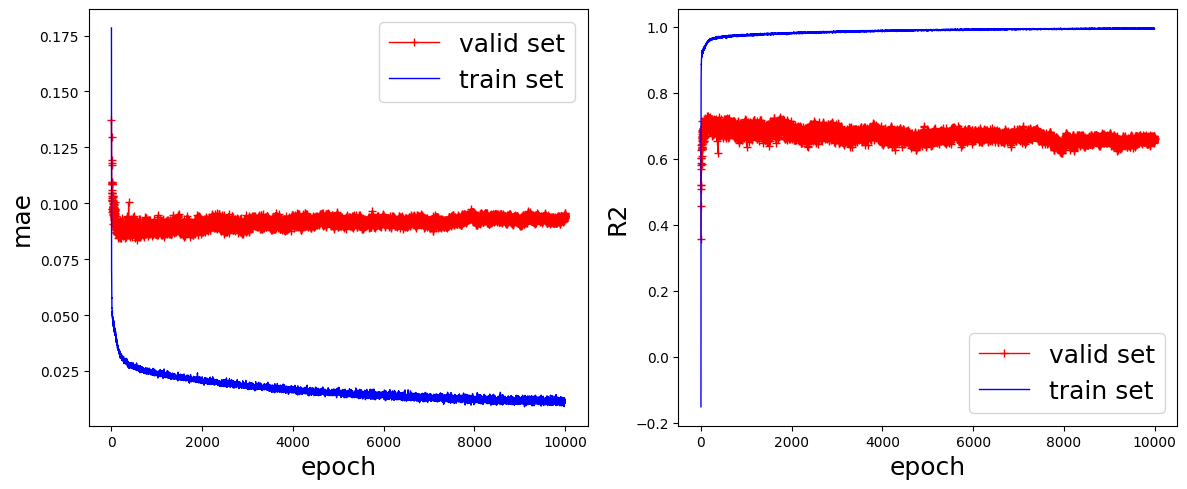

In [21]:
last_ckpt_path = path + '/last_ckpt.pt'
last_ckpt = torch.load(last_ckpt_path, map_location = 'cpu')

error_log_train = last_ckpt['train_loss']
r2_log_train = last_ckpt['train_r2']
error_log_valid = last_ckpt['valid_loss']
r2_log_valid = last_ckpt['valid_r2'] 


import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2, figsize=(12, 5))

axs[0].plot(error_log_valid, "r-+", linewidth=1, label='valid set')
axs[0].plot(error_log_train, "b-", linewidth=1, label='train set')
axs[0].set_xlabel('epoch', fontsize=18)
axs[0].set_ylabel('mae', fontsize=18)
axs[0].legend(loc='upper right', fontsize=18)

axs[1].plot(r2_log_valid, "r-+", linewidth=1, label='valid set')
axs[1].plot(r2_log_train, "b-", linewidth=1, label='train set')
axs[1].set_xlabel('epoch', fontsize=18)
axs[1].set_ylabel('R2', fontsize=18)
#axs[1].set_ylim(0, 1)
axs[1].legend(loc='lower right', fontsize=18)
#axs[1].set_ylim(-0.5, 1)


plt.tight_layout()  # tight_layout을 plt.show() 전에 호출하여 레이아웃 조정
plt.show()

## 중단된 학습 이어서 학습하기 (option)

In [ ]:
path

In [ ]:
# 중단된 학습 이어서 학습하기

from tqdm.notebook import tqdm

last_ckpt_path = path + '/last_ckpt.pt'
optimal_ckpt_path = path + '/opt_checkpoint.pt'


device = torch.device('cuda')
model = Descriptor_MLP().to(device)
loss_fn = custom_mae_loss
# loss_fn1 = sigmoid_weight_mse_for_CQ
# loss_fn2 = sigmoid_weight_mse_for_CQ
optimizer = torch.optim.Adam(model.parameters(), lr = 0.001, weight_decay = 5e-4)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size = 50, gamma= 1-0.015)
callback = CallBack(patience = 300, optimal_path = optimal_ckpt_path, last_path = last_ckpt_path)


# loss normalize
mean = torch.tensor(np.load('standardization/mean.npy')).to(device)
std = torch.tensor(np.load('standardization/std.npy')).to(device)


# class : run model
from Run_model import Run_deep_Rf as relay_run
model_deep_Rf_relay = relay_run(device=device, relay = True,
                                      model = model,
                                      loss_fn = loss_fn,
                                      optimizer = optimizer,
                                      scheduler = scheduler,
                                      callback = callback,
                                      last_ckpt_path = last_ckpt_path,
                                      total_epoch = 10000)

model_deep_Rf_relay(train_loader,valid_loader)

  0%|          | 0/2316 [00:00<?, ?it/s]

Epoch : 7685 | Train_loss : 0.0119, Train_r2 : 0.9954 | Valid_loss : 0.0770, Valid_r2 : 0.7671
Epoch : 7686 | Train_loss : 0.0124, Train_r2 : 0.9951 | Valid_loss : 0.0754, Valid_r2 : 0.7756
Epoch : 7687 | Train_loss : 0.0142, Train_r2 : 0.9934 | Valid_loss : 0.0768, Valid_r2 : 0.7671
Epoch : 7688 | Train_loss : 0.0136, Train_r2 : 0.9941 | Valid_loss : 0.0761, Valid_r2 : 0.7712
Epoch : 7689 | Train_loss : 0.0117, Train_r2 : 0.9955 | Valid_loss : 0.0764, Valid_r2 : 0.7694
Epoch : 7690 | Train_loss : 0.0128, Train_r2 : 0.9947 | Valid_loss : 0.0761, Valid_r2 : 0.7731
Epoch : 7691 | Train_loss : 0.0120, Train_r2 : 0.9952 | Valid_loss : 0.0770, Valid_r2 : 0.7662
Epoch : 7692 | Train_loss : 0.0146, Train_r2 : 0.9926 | Valid_loss : 0.0768, Valid_r2 : 0.7683
Epoch : 7693 | Train_loss : 0.0129, Train_r2 : 0.9945 | Valid_loss : 0.0770, Valid_r2 : 0.7663
Epoch : 7694 | Train_loss : 0.0131, Train_r2 : 0.9944 | Valid_loss : 0.0760, Valid_r2 : 0.7714
Epoch : 7695 | Train_loss : 0.0127, Train_r2 : 0.9

## model 불러오기

In [22]:
path

'ckpt_paper/ckpt_<C_paper_final>_<tvt>_CLI_3body_ECFP+descriptors_MLP_dropout0.3'

In [24]:
# 일반적인 모델 불러오기
train_loader = DataLoader(train_dataset, batch_size=500, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=500, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=500, shuffle=True)


opt_ckpt = torch.load((path + '/opt_checkpoint.pt'), map_location = 'cpu')


############### penalty 모델 불러오기 ######################
#########################################################
'''
start_p 전의 opt model 불러오기
opt_ckpt = torch.load('./ckpt_only_d4c_model_5s_8_penalty_by_aug_start=1000/opt_checkpoint.pt')

start_p 이후의 opt model 불러오기
opt_ckpt = torch.load('./ckpt_only_d4c_model_5s_8_penalty_by_aug_start=1000/real_opt_ckpt.pt')

start_p 이후 마지막 last model 불러오기
opt_ckpt = torch.load(('./ckpt_only_d4c_model_5s_8_penalty_by_aug_start=1000/last_ckpt.pt'))
'''
#########################################################
#########################################################

device = torch.device('cuda:3')
model = CLI_3body_ECFP_MLP(input_size = 2*(2048+6), dropout=0.3).to(device)
model.load_state_dict(opt_ckpt['model_state_dict'])


mean = np.load('./standardization/mean.npy')
std = np.load('./standardization/std.npy')

#train
train_pred=[]
train_label=[]
train_id = []
model.eval()
with torch.no_grad(): 
    for inter1, inter2, inter3, label, ratio1, ratio2, ratio3, i in train_loader:
        train_label.append(label)
        train_id.append(i)
        inter1_batch = inter1.to(device)
        inter2_batch = inter2.to(device)
        inter3_batch = inter3.to(device)
        ratio1_batch = ratio1.to(device)
        ratio2_batch = ratio2.to(device)
        ratio3_batch = ratio3.to(device)
        pred = model(inter1_batch, inter2_batch, inter3_batch, ratio1_batch, ratio2_batch, ratio3_batch)
        train_pred.append(pred.cpu())

train_label = np.vstack(train_label)
train_label = inverse_standardization(train_label, mean, std)
train_label= train_label[:, 0].reshape(-1,1)
mask = ~np.isnan(train_label)
train_label=train_label[mask]

train_pred = np.vstack(train_pred)
train_pred = inverse_standardization(train_pred, mean, std)
train_pred = train_pred.reshape(-1,1)
train_pred=train_pred[mask]


# valid
valid_pred=[]
valid_label=[]
valid_id=[]
model.eval()
with torch.no_grad():
    for inter1, inter2, inter3, label, ratio1, ratio2, ratio3, i in valid_loader:
        valid_label.append(label)
        valid_id.append(i)
        inter1_batch = inter1.to(device)
        inter2_batch = inter2.to(device)
        inter3_batch = inter3.to(device)
        ratio1_batch = ratio1.to(device)
        ratio2_batch = ratio2.to(device)
        ratio3_batch = ratio3.to(device)
        pred = model(inter1_batch, inter2_batch, inter3_batch, ratio1_batch, ratio2_batch, ratio3_batch)
        valid_pred.append(pred.cpu())

valid_label = np.vstack(valid_label)
valid_label = inverse_standardization(valid_label, mean, std)
valid_label= valid_label[:, 0].reshape(-1,1)
mask = ~np.isnan(valid_label)
valid_label=valid_label[mask]

valid_pred = np.vstack(valid_pred)
valid_pred = inverse_standardization(valid_pred, mean, std)
valid_pred = valid_pred.reshape(-1,1)
valid_pred=valid_pred[mask]


# test
test_pred=[]
test_label=[]
test_id=[]
model.eval()
with torch.no_grad():
    for inter1, inter2, inter3, label, ratio1, ratio2, ratio3, i in test_loader:
        test_label.append(label)
        test_id.append(i)
        inter1_batch = inter1.to(device)
        inter2_batch = inter2.to(device)
        inter3_batch = inter3.to(device)
        ratio1_batch = ratio1.to(device)
        ratio2_batch = ratio2.to(device)
        ratio3_batch = ratio3.to(device)
        pred = model(inter1_batch, inter2_batch, inter3_batch, ratio1_batch, ratio2_batch, ratio3_batch)
        test_pred.append(pred.cpu())

test_label = np.vstack(test_label)
test_label = inverse_standardization(test_label, mean, std)
test_label= test_label[:, 0].reshape(-1,1)
mask = ~np.isnan(test_label)
test_label=test_label[mask]

test_pred = np.vstack(test_pred)
test_pred = inverse_standardization(test_pred, mean, std)
test_pred = test_pred.reshape(-1,1)
test_pred=test_pred[mask]


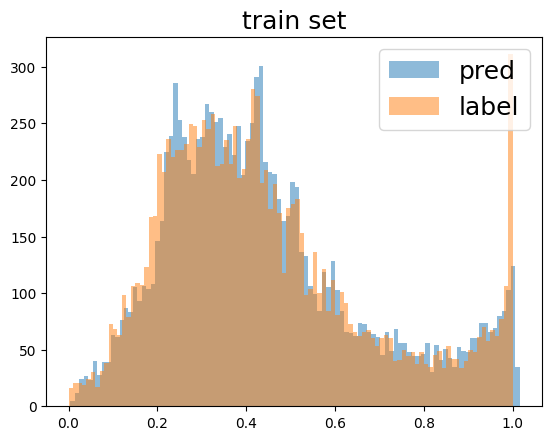

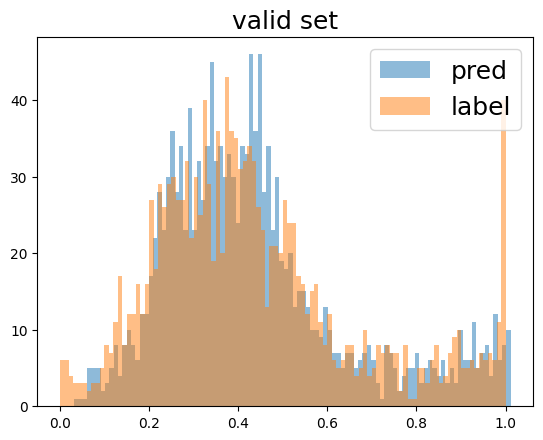

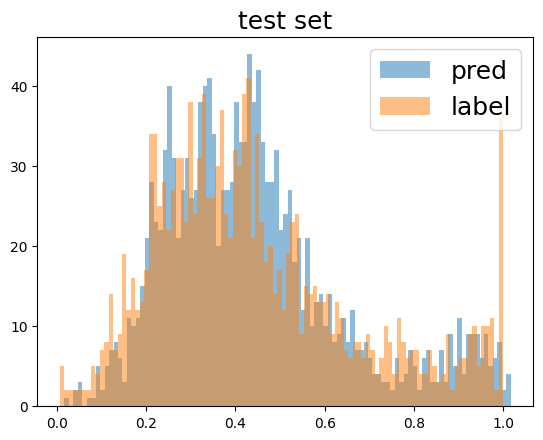

In [25]:
plt.hist(train_pred, bins=100, alpha = 0.5, label = 'pred')
plt.hist(train_label, bins=100, alpha = 0.5, label = 'label')
plt.legend(fontsize=18)
plt.title('train set' ,fontsize=18)
plt.show()
plt.hist(valid_pred, bins=100, alpha = 0.5, label = 'pred')
plt.hist(valid_label, bins=100, alpha = 0.5, label = 'label')
plt.legend(fontsize=18)
plt.title('valid set' ,fontsize=18)
plt.show()
plt.hist(test_pred, bins=100, alpha = 0.5, label = 'pred')
plt.hist(test_label, bins=100, alpha = 0.5, label = 'label')
plt.legend(fontsize=18)
plt.title('test set' ,fontsize=18)
plt.show()

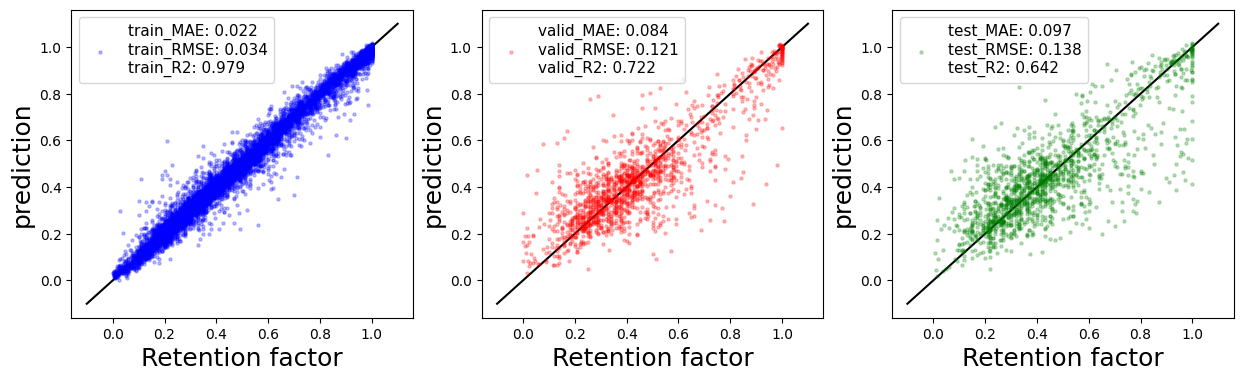

In [26]:
# Rf 라벨일 경우

def r2(preds, targets):
    mean = np.sum(targets)/len(targets)
    ss_res = np.sum((targets - preds) ** 2)
    ss_tot = np.sum((targets - mean) ** 2)
    return 1- ss_res / ss_tot 

train_mae = np.mean(np.abs(train_pred-train_label)).item()
valid_mae = np.mean(np.abs(valid_pred-valid_label)).item()
test_mae = np.mean(np.abs(test_pred-test_label)).item()

# 각 세트에 대한 RMSE
train_rmse = np.sqrt(np.mean((train_pred - train_label)**2)).item()
valid_rmse = np.sqrt(np.mean((valid_pred - valid_label)**2)).item()
test_rmse = np.sqrt(np.mean((test_pred - test_label)**2)).item()


train_r2 = r2(train_pred, train_label).item()
valid_r2 = r2(valid_pred, valid_label).item()
test_r2 = r2(test_pred, test_label).item()


import matplotlib.pyplot as plt

fig,axs = plt.subplots(1,3,figsize=(15,4))

x_line=np.linspace(-0.1,1.1,100)
y_line=x_line

for i in range(3):
    fig.set_facecolor('white')
    axs[i].plot(x_line, y_line, c='black', zorder=1)

    if i==0:
        axs[i].scatter(train_label.flatten(), train_pred.flatten(), c='blue',s=5, zorder=2, alpha = 0.25 , label = f'train_MAE: {round(train_mae,3)}\ntrain_RMSE: {round(train_rmse,3)}\ntrain_R2: {round(train_r2,3)}')
    elif i==1:
        axs[i].scatter(valid_label.flatten(), valid_pred.flatten(), c='red',s=5, zorder=3, alpha = 0.25, label = f'valid_MAE: {round(valid_mae,3)}\nvalid_RMSE: {round(valid_rmse,3)}\nvalid_R2: {round(valid_r2,3)}')
    elif i==2:
        axs[i].scatter(test_label.flatten(), test_pred.flatten(), c='green',s=5, zorder=3, alpha = 0.25, label = f'test_MAE: {round(test_mae,3)}\ntest_RMSE: {round(test_rmse,3)}\ntest_R2: {round(test_r2,3)}')
    axs[i].set_xlabel('Retention factor', fontsize = 18)
    axs[i].set_ylabel('prediction', fontsize = 18)
    axs[i].legend(loc='upper left', fontsize = 11)
    #axs[i].set_xlim(-0.1, 1.1)
    #axs[i].set_ylim(-0.1, 1.1)



In [28]:
import os
os.makedirs('Figure_data/parity_plot/CLI_3body_ECFP+descriptors' , exist_ok = False)

a = pd.DataFrame({'train_pred':train_pred, 'train_label': train_label})
b = pd.DataFrame({'valid_pred':valid_pred, 'valid_label': valid_label})
c = pd.DataFrame({'test_pred':test_pred, 'test_label': test_label})

a.to_csv('Figure_data/parity_plot/CLI_3body_ECFP+descriptors/parity_train.csv', index=False)
b.to_csv('Figure_data/parity_plot/CLI_3body_ECFP+descriptors/parity_valid.csv', index=False)
c.to_csv('Figure_data/parity_plot/CLI_3body_ECFP+descriptors/parity_test.csv', index=False)

In [ ]:
# 역 시그모이드 라벨 썼을 경우우

"""def E2Rf(E):
    return 1 / (1 + np.exp(-E))

def r2(preds, targets):
    mean = np.sum(targets)/len(targets)
    ss_res = np.sum((targets - preds) ** 2)
    ss_tot = np.sum((targets - mean) ** 2)
    return 1- ss_res / ss_tot 

train_pred = E2Rf(train_pred)
train_label = E2Rf(train_label)
valid_pred = E2Rf(valid_pred)
valid_label = E2Rf(valid_label)
test_pred = E2Rf(test_pred)
test_label = E2Rf(test_label)

train_mae = np.mean(np.abs(train_pred-train_label)).item()
valid_mae = np.mean(np.abs(valid_pred-valid_label)).item()
test_mae = np.mean(np.abs(test_pred-test_label)).item()

train_r2 = r2(train_pred, train_label).item()
valid_r2 = r2(valid_pred, valid_label).item()
test_r2 = r2(test_pred, test_label).item()


import matplotlib.pyplot as plt

fig,axs = plt.subplots(1,3,figsize=(15,4))

x_line=x_line = np.linspace(-0.1, 1.1, 100)
y_line=x_line

for i in range(3):
    fig.set_facecolor('white')
    axs[i].plot(x_line, y_line, c='black', zorder=1)
    if i==0:
        axs[i].scatter(train_label.flatten(), train_pred.flatten(), c='blue',s=5, zorder=2, alpha = 0.25 , label = f'train_MAE: {round(train_mae,3)}\ntrain_R2: {round(train_r2,3)}')
    elif i==1:
        axs[i].scatter(valid_label.flatten(), valid_pred.flatten(), c='red',s=5, zorder=3, alpha = 0.25, label = f'valid_MAE: {round(valid_mae,3)}\nvalid_R2: {round(valid_r2,3)}')
    elif i==2:
        axs[i].scatter(test_label.flatten(), test_pred.flatten(), c='green',s=5, zorder=3, alpha = 0.25, label = f'test_MAE: {round(test_mae,3)}\ntest_R2: {round(test_r2,3)}')
    axs[i].set_xlabel('Retention factor', fontsize = 18)
    axs[i].set_ylabel('prediction', fontsize = 18)
    axs[i].legend(loc='upper left', fontsize = 11)
    #axs[i].set_xlim(-0.1, 1.1)
    #axs[i].set_ylim(-0.1, 1.1)"""

## outlier 조사(shuffle = False) 및 기타 분석 

In [23]:
train_index = np.hstack([np.asarray(id_tensor.view(-1)) for id_tensor in train_id])
train_pred_manager = dict(zip(train_index, train_pred))

from copy import deepcopy

train_set_check = deepcopy(train_set)
train_pred_ = [train_pred_manager[i] for i in train_set['sample_id']]
train_set_check['train_pred'] = train_pred_
train_set_check['error'] = train_set_check['Rf'] - train_set_check['train_pred']
train_set_check

,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,Rf_type,DataSource,doi,sample_id,train_pred,error
0,Br/C(=C\C1SCCCS1)c1ccccc1,CCCCCC,CCOC(C)=O,0.937438,0.062562,0.580000,C,D4C,average of several papers,0,0.601605,-0.021605
1,BrC/C=C\COC1CCCCO1,CCCCCC,CCOCC,0.650419,0.349581,0.690000,C,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.4...,2,0.679696,0.010304
2,BrC1=C(Br)C(c2ccccc2)OC1,CCCCCC,CCOC(C)=O,0.749803,0.250197,0.780000,C,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...,3,0.820791,-0.040791
3,BrCCCCCCNc1ccccc1,CCCCCC,CCOC(C)=O,0.789299,0.210701,0.480000,C,D4C,average of several papers,6,0.489767,-0.009767
4,BrCCc1cccc2ccccc12,CCCCCC,CCOC(C)=O,0.882244,0.117756,0.630000,C,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...,7,0.585308,0.044692
...,...,...,...,...,...,...,...,...,...,...,...,...
11792,c1ccc(-c2ccccn2)nc1,ClCCl,CO,0.984461,0.015539,0.052081,C,benchmark,exp (benchmark,14696,0.035754,0.016327
11793,c1ccc(CNCc2ccccc2)cc1,CCCCCC,CCOCC,0.443636,0.556364,0.280306,C,benchmark,exp (benchmark,14697,0.242087,0.038219
11794,c1ccc(CNCc2ccccc2)cc1,CCCCCC,CCOCC,0.614610,0.385390,0.185208,C,benchmark,exp (benchmark,14698,0.177956,0.007252
11795,c1ccc2[nH]ccc2c1,CCCCCC,CCOCC,0.443636,0.556364,0.764446,C,benchmark,exp (benchmark,14699,0.776344,-0.011898


In [ ]:
valid_index = np.hstack([np.asarray(id_tensor.view(-1)) for id_tensor in valid_id])
valid_pred_manager = dict(zip(valid_index, valid_pred))

from copy import deepcopy

valid_set_check = deepcopy(valid_set)
valid_pred_ = [valid_pred_manager[i] for i in valid_set['sample_id']]
valid_set_check['valid_pred'] = valid_pred_
valid_set_check['error'] = valid_set_check['Rf'] - valid_set_check['valid_pred']
valid_set_check

,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,Rf_type,DataSource,doi,sample_id,valid_pred,error
0,BrC1C(Br)(Br)C12CCOCC2,CCCCC,CCOCC,0.890324,0.109676,0.500000,C,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...,5,0.550998,-0.050998
1,Brc1ccc(/C(=N\C(c2ccccc2)c2ccccc2)N2CCOCC2)cc1,CCCCCC,CCOC(C)=O,0.428314,0.571686,0.670000,C,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.4...,16,0.555750,0.114250
2,Brc1nc2ccccc2c(Br)c1Br,CCCCCC,CCOCC,0.975532,0.024468,0.230000,C,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...,72,0.312004,-0.082004
3,C#CC#CC(OCC#CC)c1cccc(C)c1,CCCCCC,CCOC(C)=O,0.973999,0.026001,0.380000,C,D4C,average of several papers,77,0.450354,-0.070354
4,C#CC(O)c1ccc(OC)cc1,CCCCC,CCOC(C)=O,0.772206,0.227794,0.420000,C,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...,94,0.424398,-0.004398
...,...,...,...,...,...,...,...,...,...,...,...,...
1435,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.863674,0.136326,0.103807,C,benchmark,exp (benchmark,14706,0.615930,-0.512123
1436,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.926851,0.073149,0.077242,C,benchmark,exp (benchmark,14707,0.442823,-0.365581
1437,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.950015,0.049985,0.040824,C,benchmark,exp (benchmark,14708,0.238430,-0.197606
1438,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.969397,0.030603,0.045959,C,benchmark,exp (benchmark,14709,0.127420,-0.081461


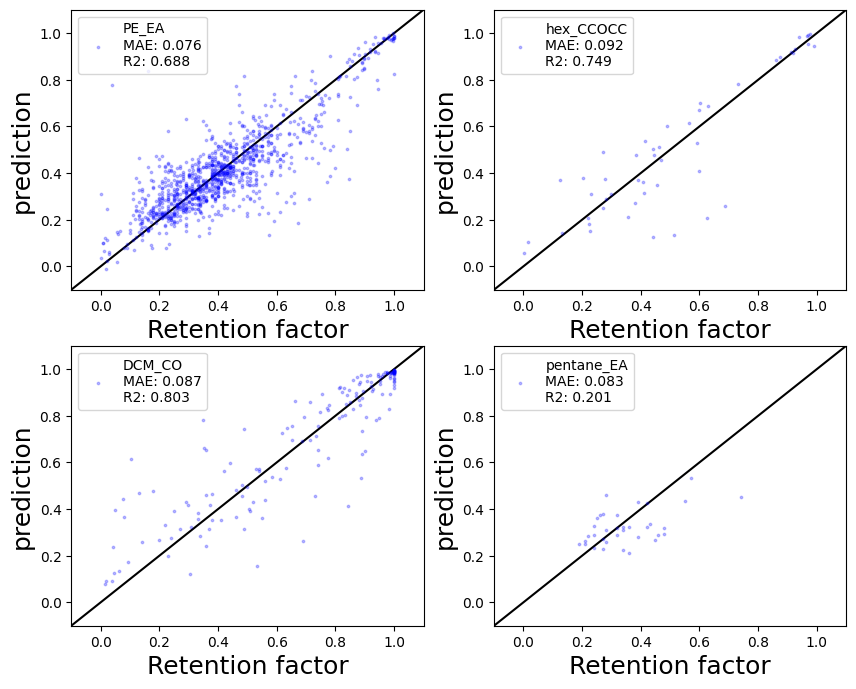

In [25]:
PE_EA_mask = [set(valid_set_check.loc[i, ['elu1_smiles','elu2_smiles']]) == {'CCOC(C)=O', 'CCCCCC'} for i in valid_set_check.index]
valid_set_check_PE_EA = valid_set_check[PE_EA_mask]

DCM_CO_mask = [set(valid_set_check.loc[i, ['elu1_smiles','elu2_smiles']]) == {'ClCCl', 'CO'} for i in valid_set_check.index]
valid_set_check_DCM_CO = valid_set_check[DCM_CO_mask]

hex_CCOCC_mask = [set(valid_set_check.loc[i, ['elu1_smiles','elu2_smiles']]) == {'CCCCCC', 'CCOCC'} for i in valid_set_check.index]
valid_set_check_hex_CCOCC = valid_set_check[hex_CCOCC_mask]

pentane_EA_mask = [set(valid_set_check.loc[i, ['elu1_smiles','elu2_smiles']]) == {'CCCCC', 'CCOC(C)=O'} for i in valid_set_check.index]
valid_set_check_pentane_EA = valid_set_check[pentane_EA_mask]

elu_sys_valid = [valid_set_check_PE_EA, valid_set_check_DCM_CO, valid_set_check_hex_CCOCC, valid_set_check_pentane_EA]
elu_sys_list = ['PE_EA', 'DCM_CO', 'hex_CCOCC', 'pentane_EA']

def mae_(preds, targets):
    return round(np.mean(np.abs(preds-targets)), 3)

def r2(preds, targets):
    mean = np.sum(targets)/len(targets)
    ss_res = np.sum((targets - preds) ** 2)
    ss_tot = np.sum((targets - mean) ** 2)
    return round(1- ss_res / ss_tot, 3)

    

import matplotlib.pyplot as plt

fig,axs = plt.subplots(2,2,figsize=(10,8))

x_line=np.arange(-2,3)
y_line=np.arange(-2,3)

for i in range(4):
    fig.set_facecolor('white')
    axs[i%2, i//2].plot(x_line, y_line, c='black', zorder=1)

    axs[i%2, i//2].scatter(
        elu_sys_valid[i]['Rf'], elu_sys_valid[i]['valid_pred'],
        c='blue',s=3, zorder=2, alpha = 0.25,
        label = f'{elu_sys_list[i]}\nMAE: {mae_(elu_sys_valid[i]["valid_pred"], elu_sys_valid[i]["Rf"])}\nR2: {r2(elu_sys_valid[i]["valid_pred"], elu_sys_valid[i]["Rf"])}')
    axs[i%2, i//2].set_xlabel('Retention factor', fontsize = 18)
    axs[i%2, i//2].set_ylabel('prediction', fontsize = 18)
    axs[i%2, i//2].legend(loc='upper left', fontsize = 10)

    axs[i%2, i//2].set_xlim(-0.1, 1.1)
    axs[i%2, i//2].set_ylim(-0.1, 1.1)

## TLC의 화학적 분석

In [ ]:
# ==============================
# 경향성 및 분석 용 set 

In [21]:
united_

,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,Rf_type,DataSource,doi
0,Br/C(=C\C1SCCCS1)c1ccccc1,CCCCCC,CCOC(C)=O,0.937438,0.062562,0.580000,C,D4C,average of several papers
1,BrC(Br)=Cn1c2ccccc2c2ccccc21,CCCCC,CCOC(C)=O,0.884089,0.115911,0.900000,C,D4C,average of several papers
2,BrC/C=C\COC1CCCCO1,CCCCCC,CCOCC,0.650419,0.349581,0.690000,C,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.4...
3,BrC1=C(Br)C(c2ccccc2)OC1,CCCCCC,CCOC(C)=O,0.749803,0.250197,0.780000,C,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...
4,BrC1=C[SH](c2ccccc2)C=N1,CCCCCC,CCOC(C)=O,0.870849,0.129151,0.450000,C,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.5...
...,...,...,...,...,...,...,...,...,...
14706,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.863674,0.136326,0.103807,C,benchmark,exp (benchmark
14707,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.926851,0.073149,0.077242,C,benchmark,exp (benchmark
14708,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.950015,0.049985,0.040824,C,benchmark,exp (benchmark
14709,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.969397,0.030603,0.045959,C,benchmark,exp (benchmark


In [22]:
valid_uniq_smiles_list = list(united_['Smiles'].drop_duplicates())

aug_smiles = [smiles  for smiles in valid_uniq_smiles_list for i in range(11)]
aug_elu1_smiles = ['CCOC(C)=O' for i in range(len(aug_smiles))]
aug_elu2_smiles = ['CCCCCC' for i in range(len(aug_smiles))]
aug_ratio1 = [round(i,1) for ii in range(len(valid_uniq_smiles_list)) for i in np.arange(0,1.05,0.1)]
aug_ratio2 = np.round(1- np.array(aug_ratio1), 1)

trend_set = pd.DataFrame({
    'Smiles': aug_smiles,
    'elu1_smiles':aug_elu1_smiles,
    'elu2_smiles':aug_elu2_smiles,
    'ratio1':aug_ratio1,
    'ratio2':aug_ratio2,
    'Rf':[np.nan for i in range(len(aug_smiles))]
})

trend_set['sample_id'] = trend_set.index
trend_set

,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,sample_id
0,Br/C(=C\C1SCCCS1)c1ccccc1,CCOC(C)=O,CCCCCC,0.0,1.0,NaN,0
1,Br/C(=C\C1SCCCS1)c1ccccc1,CCOC(C)=O,CCCCCC,0.1,0.9,NaN,1
2,Br/C(=C\C1SCCCS1)c1ccccc1,CCOC(C)=O,CCCCCC,0.2,0.8,NaN,2
3,Br/C(=C\C1SCCCS1)c1ccccc1,CCOC(C)=O,CCCCCC,0.3,0.7,NaN,3
4,Br/C(=C\C1SCCCS1)c1ccccc1,CCOC(C)=O,CCCCCC,0.4,0.6,NaN,4
...,...,...,...,...,...,...,...
126341,c1cnc2c(c1)ccc1cccnc12,CCOC(C)=O,CCCCCC,0.6,0.4,NaN,126341
126342,c1cnc2c(c1)ccc1cccnc12,CCOC(C)=O,CCCCCC,0.7,0.3,NaN,126342
126343,c1cnc2c(c1)ccc1cccnc12,CCOC(C)=O,CCCCCC,0.8,0.2,NaN,126343
126344,c1cnc2c(c1)ccc1cccnc12,CCOC(C)=O,CCCCCC,0.9,0.1,NaN,126344


In [ ]:
trend_set.to_csv('/home/ufslab223/Shared/KSW/torch_geometric/TLC_RF/DB/Rf/United_DB_trend_test.csv')

In [31]:
trend_set = pd.read_csv('/home/ufslab223/Shared/KSW/torch_geometric/TLC_RF/DB/Rf/United_DB_trend_test.csv')

In [43]:
trend_input

array([[ 0.     ,  0.     ,  0.     , ...,  0.     ,  2.5866 ,  0.     ],
       [ 0.     ,  0.     ,  0.     , ...,  0.2    ,  2.38488,  2.63   ],
       [ 0.     ,  0.     ,  0.     , ...,  0.4    ,  2.18316,  5.26   ],
       ...,
       [ 0.     ,  0.     ,  0.     , ...,  1.6    ,  0.97284, 21.04   ],
       [ 0.     ,  0.     ,  0.     , ...,  1.8    ,  0.77112, 23.67   ],
       [ 0.     ,  0.     ,  0.     , ...,  2.     ,  0.5694 , 26.3    ]])

In [51]:
# 경향성 test


device = torch.device('cuda')
model = Descriptor_MLP(dropout=0.3)

opt_ckpt = torch.load((path + '/opt_checkpoint.pt'), map_location = 'cpu')
model.load_state_dict(opt_ckpt['model_state_dict'])
model = model.to(device)


mean = np.load('./standardization/mean.npy')
std = np.load('./standardization/std.npy')


# ====================================================
# print('>>> input 만드는 중...')

trend_input = compound_mixed_eluent_vector(trend_set, 'elu1_smiles', 'ratio1', 'elu2_smiles', 'ratio2')
# MinMaxScaler
# scaler는 train 기준으로 위에서 학습해둔거ㅏ
trend_input = scaler.transform(trend_input)
# label
trend_label = (np.array(trend_set['Rf']).reshape(-1,1)-mean)/std

#=====================================================
print('>>> dataloader 만드는 중...')


trend_dataset = TensorDataset(torch.tensor(trend_input, dtype=torch.float32), torch.tensor(trend_label, dtype=torch.float32), torch.tensor(trend_set['sample_id'].values, dtype=torch.long))
trend_loader = DataLoader(trend_dataset, batch_size=500, shuffle=False)

# ====================================================
print('>>> 예측 시작!')

trend_pred=[]
trend_id=[]
model.eval()
with torch.no_grad():
    for x,y,i in trend_loader:
        trend_id.append(i)
        x_batch = x.to(device)
        pred = model(x_batch)
        trend_pred.append(pred.cpu())

trend_pred = np.vstack(trend_pred)
trend_pred = inverse_standardization(trend_pred, mean, std)
trend_pred = trend_pred.reshape(-1)

print('>> 예측 완료')

  0%|          | 0/126346 [00:00<?, ?it/s]

  0%|          | 0/126346 [00:00<?, ?it/s]

  0%|          | 0/126346 [00:00<?, ?it/s]

>>> dataloader 만드는 중...
>>> 예측 시작!
>> 예측 완료


In [52]:
trend_pred

array([0.52960503, 0.62450063, 0.64943445, ..., 0.7410121 , 0.6058985 ,
       0.50192416], dtype=float32)

In [54]:
trend_pred = np.clip(trend_pred,0,1)

In [55]:
trend_index = np.hstack([np.asarray(id_tensor.view(-1)) for id_tensor in trend_id])
trend_pred_manager = dict(zip(trend_index, trend_pred.reshape(-1)))

from copy import deepcopy

trend_set_check = deepcopy(trend_set)
trend_pred_ = [trend_pred_manager[i] for i in trend_set['sample_id']]
trend_set_check['trend_pred'] = trend_pred_
trend_set_check

,Unnamed: 0,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,sample_id,trend_pred
0,0,Br/C(=C\C1SCCCS1)c1ccccc1,CCOC(C)=O,CCCCCC,0.0,1.0,NaN,0,0.529605
1,1,Br/C(=C\C1SCCCS1)c1ccccc1,CCOC(C)=O,CCCCCC,0.1,0.9,NaN,1,0.624501
2,2,Br/C(=C\C1SCCCS1)c1ccccc1,CCOC(C)=O,CCCCCC,0.2,0.8,NaN,2,0.649434
3,3,Br/C(=C\C1SCCCS1)c1ccccc1,CCOC(C)=O,CCCCCC,0.3,0.7,NaN,3,0.613183
4,4,Br/C(=C\C1SCCCS1)c1ccccc1,CCOC(C)=O,CCCCCC,0.4,0.6,NaN,4,0.560088
...,...,...,...,...,...,...,...,...,...
126341,126341,c1cnc2c(c1)ccc1cccnc12,CCOC(C)=O,CCCCCC,0.6,0.4,NaN,126341,0.668511
126342,126342,c1cnc2c(c1)ccc1cccnc12,CCOC(C)=O,CCCCCC,0.7,0.3,NaN,126342,0.766078
126343,126343,c1cnc2c(c1)ccc1cccnc12,CCOC(C)=O,CCCCCC,0.8,0.2,NaN,126343,0.741012
126344,126344,c1cnc2c(c1)ccc1cccnc12,CCOC(C)=O,CCCCCC,0.9,0.1,NaN,126344,0.605898


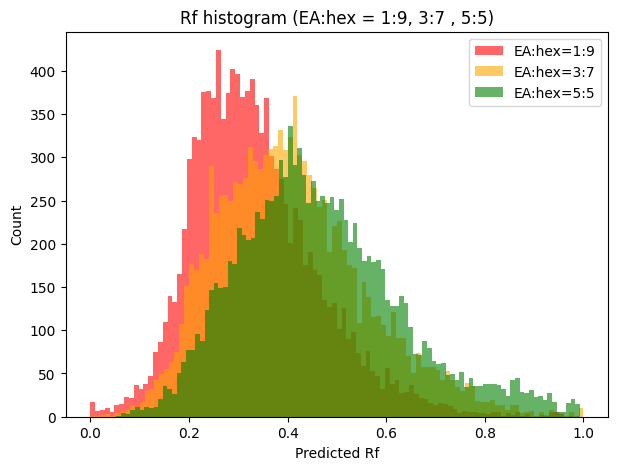

In [56]:
#hists = [list(trend_set_check[trend_set_check['ratio1']==np.round(i,1)]['trend_pred']) for i in np.arange(0,1.05,0.1)]
hists = [list(trend_set_check[trend_set_check['ratio1']==np.round(i,1)]['trend_pred']) for i in [0.1, 0.3, 0.5]]

fig = plt.figure(figsize=(7,5))
color=['red', 'orange', 'green']
data_label = ['1:9', '3:7', '5:5']
for i, data in enumerate(hists):
    plt.hist(
        data,
        alpha=0.6,
        bins = 100,
        color = color[i],
        density=False,
        label=f'EA:hex={data_label[i]}')

plt.title('Rf histogram (EA:hex = 1:9, 3:7 , 5:5)')
plt.xlabel('Predicted Rf')
plt.ylabel('Count')
plt.legend()
plt.show()


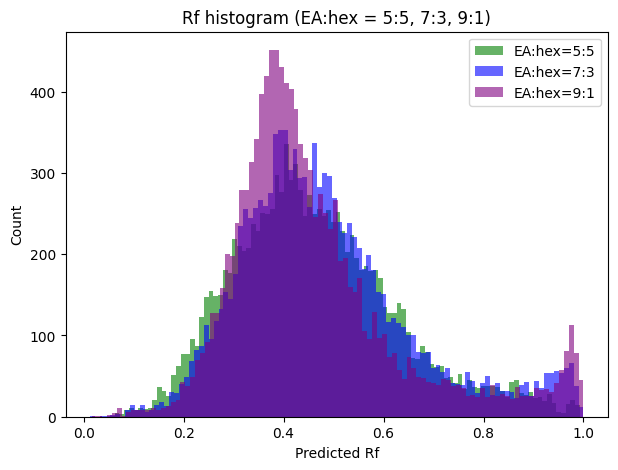

In [57]:
#hists = [list(trend_set_check[trend_set_check['ratio1']==np.round(i,1)]['trend_pred']) for i in np.arange(0,1.05,0.1)]
hists = [list(trend_set_check[trend_set_check['ratio1']==np.round(i,1)]['trend_pred']) for i in [0.5, 0.7, 0.9]]

fig = plt.figure(figsize=(7,5))
color=['green', 'blue', 'purple']
data_label = ['5:5', '7:3', '9:1']
for i, data in enumerate(hists):
    plt.hist(
        data,
        alpha=0.6,
        bins = 100,
        color = color[i],
        density=False,
        label=f'EA:hex={data_label[i]}')

plt.title('Rf histogram (EA:hex = 5:5, 7:3, 9:1)')
plt.xlabel('Predicted Rf')
plt.ylabel('Count')
plt.legend()
plt.show()

In [37]:
trend_set_check

,Unnamed: 0,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,sample_id,trend_pred
0,0,Br/C(=C\C1SCCCS1)c1ccccc1,CCOC(C)=O,CCCCCC,0.0,1.0,NaN,0,0.0
1,1,Br/C(=C\C1SCCCS1)c1ccccc1,CCOC(C)=O,CCCCCC,0.1,0.9,NaN,1,0.0
2,2,Br/C(=C\C1SCCCS1)c1ccccc1,CCOC(C)=O,CCCCCC,0.2,0.8,NaN,2,0.0
3,3,Br/C(=C\C1SCCCS1)c1ccccc1,CCOC(C)=O,CCCCCC,0.3,0.7,NaN,3,0.0
4,4,Br/C(=C\C1SCCCS1)c1ccccc1,CCOC(C)=O,CCCCCC,0.4,0.6,NaN,4,0.0
...,...,...,...,...,...,...,...,...,...
126341,126341,c1cnc2c(c1)ccc1cccnc12,CCOC(C)=O,CCCCCC,0.6,0.4,NaN,126341,0.0
126342,126342,c1cnc2c(c1)ccc1cccnc12,CCOC(C)=O,CCCCCC,0.7,0.3,NaN,126342,0.0
126343,126343,c1cnc2c(c1)ccc1cccnc12,CCOC(C)=O,CCCCCC,0.8,0.2,NaN,126343,0.0
126344,126344,c1cnc2c(c1)ccc1cccnc12,CCOC(C)=O,CCCCCC,0.9,0.1,NaN,126344,0.0


In [58]:
# Rf trajectory (EA ratio 0~1)
rf_trace_list = np.array([list(trend_set_check['trend_pred'][11*i:11*(i+1)]) for i in range(len(valid_uniq_smiles_list))] )

# Rf mean (EA ratio 0~1)
rf_level = rf_trace_list.mean(axis=1, keepdims=True)

# Rf range (EA ratio 0~1)
rf_amplitude = (rf_trace_list.max(axis=1) - rf_trace_list.min(axis=1)).reshape(-1,1)

# Rf start,end (EA ratio0~1)
rf_end2end = rf_trace_list[:,[0,10]]

# Rf trajectory shape (EA ratio 0~1)
# L2 norm으로 나누어서 11차원 벡터의 크기를 제거하고 방향만 남김 --> 즉 shape만 남김
rf_delta_list=np.diff(rf_trace_list, axis=1)
delta_L2_norm = np.linalg.norm(rf_delta_list, axis=1, keepdims=True)
rf_trace_shape = rf_delta_list/delta_L2_norm

#X = np.hstack([rf_level, rf_amplitude, rf_trace_shape])
#X = np.hstack([rf_amplitude,rf_trace_shape])
#X = np.hstack([rf_trace_list,rf_trace_shape])
X = np.hstack([rf_trace_list])

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# X_scaled[:,0] *= 0.5   # level weight
# X_scaled[:,1] *= 1.0   # amplitude weight
# X_scaled[:,2:] *= 2.0  # shape weight
# X_scaled[:,3:] *= 2.0  # shape weight


In [59]:
from sklearn.cluster import KMeans

k = 4  # 보통 3~6 사이에서 elbow로 결정
kmeans = KMeans(n_clusters=k, random_state=0)
labels = kmeans.fit_predict(X)

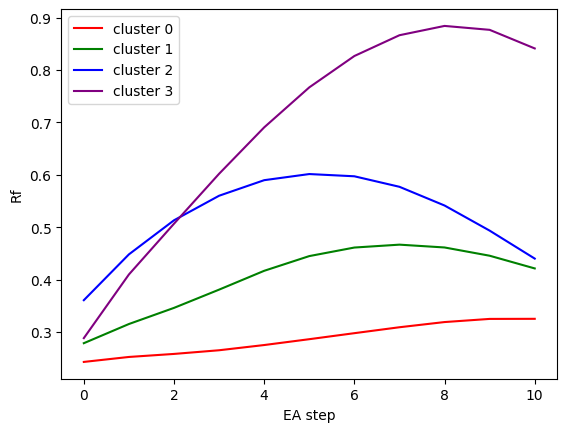

In [60]:
cluster_means = []

for c in range(k):
    mean_trace = np.array(rf_trace_list)[labels == c].mean(axis=0)
    cluster_means.append(mean_trace.mean())   # 전체 평균 Rf

order = np.argsort(cluster_means)

label_map = {old:new for new, old in enumerate(order)}

new_labels = np.array([label_map[l] for l in labels])

import matplotlib.pyplot as plt
color= ['red', 'green', 'blue', 'purple']
for i,c in enumerate(range(k)):
    mean_trace = np.array(rf_trace_list)[new_labels == c].mean(axis=0)
    plt.plot(mean_trace, color = color[i], label=f'cluster {c}')

plt.legend()
plt.xlabel('EA step')
plt.ylabel('Rf')
plt.show()

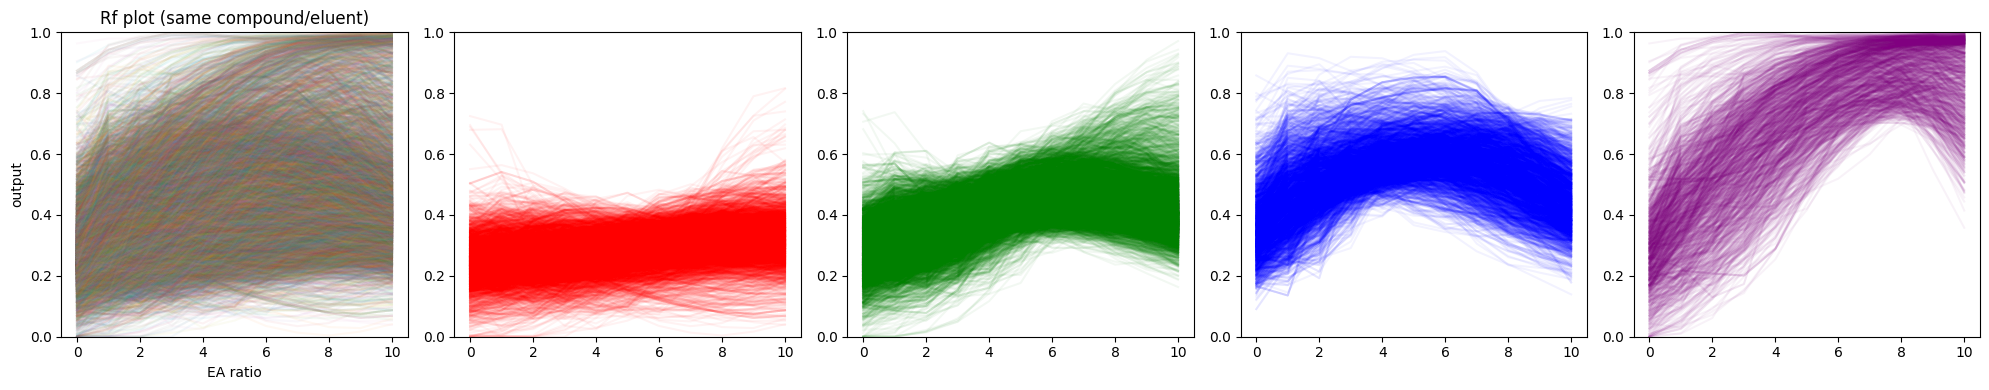

In [61]:
# ============== 같은 분자 내에서 용매 비율 비교 ==========================

rf_trace_list = [list(trend_set_check['trend_pred'][11*i:11*(i+1)]) for i in range(len(valid_uniq_smiles_list))] 


fig, axs = plt.subplots(1,5,figsize=(20,4))
for i, data in enumerate(rf_trace_list):
    axs[0].plot(
        np.arange(0,11,1),
        data,
        alpha=0.05,
    )
axs[0].set_title('Rf plot (same compound/eluent)')
axs[0].set_xlabel('EA ratio')
axs[0].set_ylabel('output')
axs[0].set_ylim(0,1)
for output, group in zip(rf_trace_list, new_labels):
# for output, group in zip(rf_trace_list, labels[30000:len(valid_uniq_smiles_list)]):
    if group==0:
        color = 'red'
        alpha = 0.05
        axs[1].plot(np.arange(0,11,1), output, color = color, alpha=alpha)
        axs[1].set_ylim(0,1)
    elif group==1:
        color = 'green'
        alpha = 0.05
        axs[2].plot(np.arange(0,11,1), output, color = color, alpha=alpha)
        axs[2].set_ylim(0,1)
    elif group==2:
        color = 'blue'
        alpha = 0.05
        axs[3].plot(np.arange(0,11,1), output, color = color, alpha=alpha)
        axs[3].set_ylim(0,1)
    elif group==3:
        color = 'purple'
        alpha = 0.05
        axs[4].plot(np.arange(0,11,1), output, color = color, alpha=alpha)
        axs[4].set_ylim(0,1)
    # elif group==4:
    #     color = 'black'
    #     alpha = 0.05
    #     axs[5].plot(np.arange(0,11,1), output, color = color, alpha=alpha)
    #     axs[5].set_ylim(0,1)
    # elif group==5:
    #     color = 'gray'
    #     alpha = 0.05
    #     axs[6].plot(np.arange(0,11,1), output, color = color, alpha=alpha)
    #     axs[6].set_ylim(0,1)



# axs[1].set_title('output plot (same compound/eluent)')
# axs[1].set_xlabel('EA ratio')
# axs[1].set_ylabel('model output')

plt.tight_layout()
plt.show()

In [62]:
group0=[]
group1=[]
group2=[]
group3=[]
# group4=[]
# group5=[]
for smiles,group in zip(valid_uniq_smiles_list, new_labels):
    if group ==0:
        group0.append(smiles)
    elif group ==1:
        group1.append(smiles)
    elif group==2:
        group2.append(smiles)
    elif group==3:
        group3.append(smiles)
    # elif group==4:
    #     group4.append(smiles)
    # elif group==5:
    #     group5.append(smiles)

/home/ufslab223/anaconda3/envs/ksw_pyg/lib/python3.10/site-packages/rdkit/Chem/Draw/IPythonConsole.py:343: UserWarning: Truncating the list of molecules to be displayed to 50. Change the maxMols value to display more.
  warnings.warn(


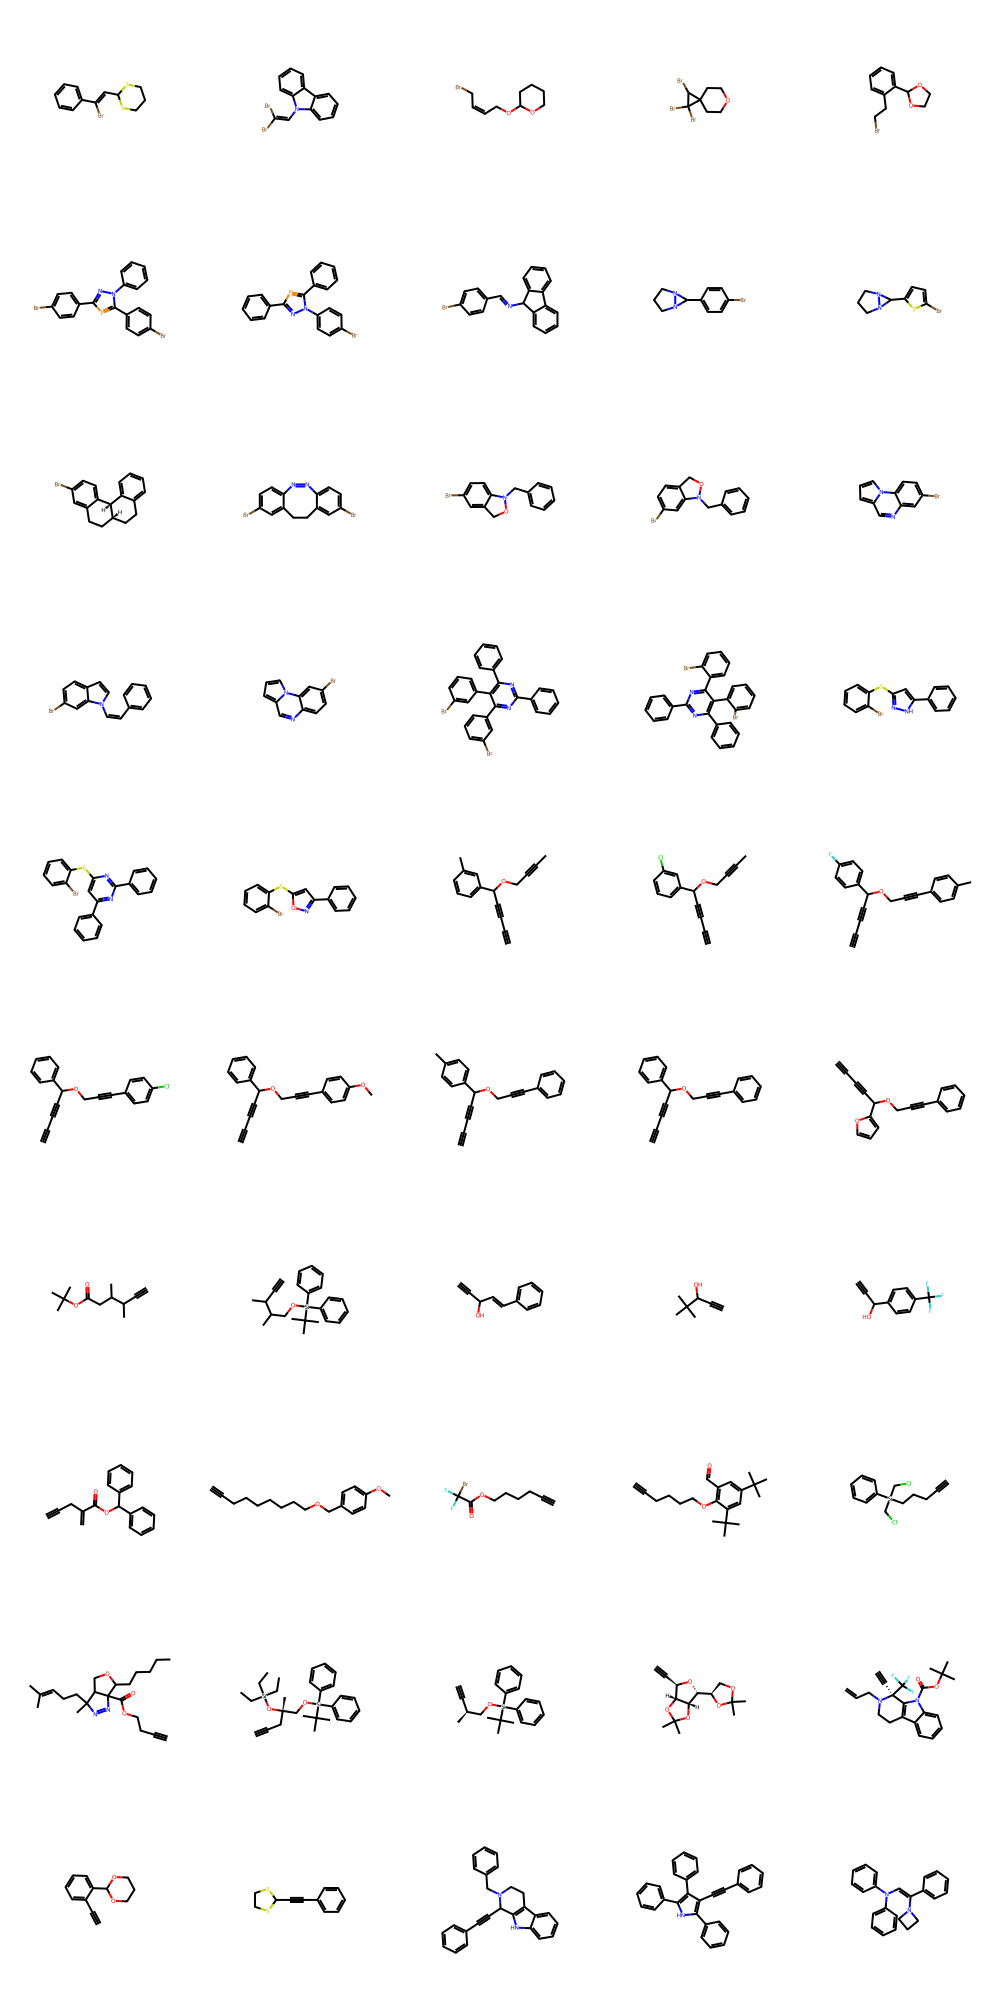

In [63]:
from rdkit import Chem
from rdkit.Chem import Draw

mols = [Chem.MolFromSmiles(smi) for smi in group2]
img = Draw.MolsToGridImage(mols, molsPerRow=5, subImgSize=(200,200))
img

In [64]:
# def get_HB_per_conjugated_atom_count(smiles):

#     mol = Chem.MolFromSmiles(smiles)
#     if mol is None:
#         return None

#     # 방향족 원자 수 카운트
#     aromatic_atom_count = sum(1 for atom in mol.GetAtoms() if atom.GetIsAromatic())

#     # 공액에 참여하는 atom 수
#     conjugated_atom_idxs = set()
#     for bond in mol.GetBonds():
#         if bond.GetIsConjugated():
#             conjugated_atom_idxs.add(bond.GetBeginAtomIdx())
#             conjugated_atom_idxs.add(bond.GetEndAtomIdx())

#     # 공액계 추정: 방향족+이중결합 원자
#     conj_atom_count = aromatic_atom_count + len(double_bond_atom_idxs)
#     return conj_atom_count

def hba(smiles):
    mol = Chem.MolFromSmiles(smiles)
    hba = Chem.rdMolDescriptors.CalcNumHBA(mol)
    return hba

def hbd(smiles):
    mol = Chem.MolFromSmiles(smiles)
    hbd = Chem.rdMolDescriptors.CalcNumHBD(mol)
    return hbd

def hb(smiles):
    mol = Chem.MolFromSmiles(smiles)
    hbd = Chem.rdMolDescriptors.CalcNumHBD(mol)
    hba = Chem.rdMolDescriptors.CalcNumHBA(mol)
    return hba+hbd

def tpsa(smiles):
    mol = Chem.MolFromSmiles(smiles)
    tpsa = Descriptors.TPSA(mol)
    return tpsa

def asa(smiles):
    mol = Chem.MolFromSmiles(smiles)
    asa = rdMolDescriptors.CalcLabuteASA(mol)
    return asa

def mw(smiles):
    mol = Chem.MolFromSmiles(smiles)
    mw = Descriptors.MolWt(mol)
    return mw


In [ ]:
"""from rdkit import Chem
from rdkit.Chem import AllChem, rdFreeSASA

def surface_area(smiles):
    mol = Chem.MolFromSmiles(smiles)
    mol = Chem.AddHs(mol) # 수소 원자 추가 필수
    AllChem.EmbedMolecule(mol) # 3D 구조 생성

    # 원자 반지름 리스트 추출
    radii = rdFreeSASA.classifyAtoms(mol)

    # SASA 계산
    sasa = rdFreeSASA.CalcSASA(mol, radii)
    return sasa"""

In [ ]:
print(len(group0)/len(group1),len(group1)/len(group1), len(group2)/len(group1))

4.139673105497772 1.0 3.3937592867756314


0
1
2
3


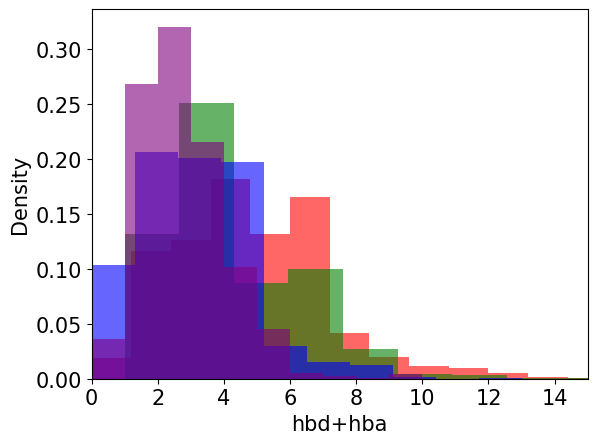

In [65]:

g0 = list(map(hb, group0))

g1 = list(map(hb, group1))

g2 = list(map(hb, group2))

g3 = list(map(hb, group3))

# g4 = list(map(polarity_per_mol, group4))

# g5 = list(map(polarity_per_mol, group5))

gs = [g0, g1,g2,g3]#,g4,g5]

color= ['red', 'green', 'blue','purple']#, 'black', 'gray']
bin = [30,20,10,10]
for i, data in enumerate(gs):
    print(i)
    plt.hist(
        data,
        color=color[i],
        bins=bin[i],
        alpha = 0.6,
        density=True
    )
plt.xlabel('hbd+hba', size = 15)
plt.ylabel('Density', size = 15)
plt.xticks(size = 15)
plt.yticks(size = 15)
plt.xlim(0,15)
plt.show()

0
1
2
3


(0.0, 200.0)

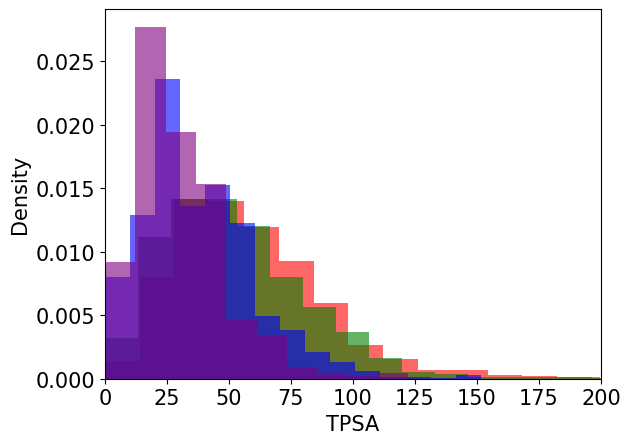

In [66]:

g0 = list(map(tpsa, group0))

g1 = list(map(tpsa, group1))

g2 = list(map(tpsa, group2))

g3 = list(map(tpsa, group3))

# g4 = list(map(polarity_per_mol, group4))

# g5 = list(map(polarity_per_mol, group5))

gs = [g0, g1,g2,g3]#,g4,g5]

color= ['red', 'green', 'blue', 'purple']#, 'black', 'gray']
bin = [30,30,15,10]
for i, data in enumerate(gs):
    print(i)
    plt.hist(
        data,
        color=color[i],
        bins=bin[i],
        alpha = 0.6,
        density=True
    )
plt.xlabel('TPSA', size = 15)
plt.ylabel('Density', size = 15)
plt.xticks(size = 15)
plt.yticks(size = 15)
plt.xlim(0,200)

In [ ]:
# T-sne
# 기존 D4C 데이터베이스와 비교
from rdkit.Chem import rdFingerprintGenerator
from rdkit import DataStructs
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
from tqdm import tqdm


total = group1+group2+group3

generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048, countSimulation=True)
X = []
for smiles in tqdm(total):
    mol = Chem.MolFromSmiles(smiles)
    if mol is not None:
        fp = generator.GetFingerprint(mol)
        arr = np.zeros((2048,), dtype=int)
        DataStructs.ConvertToNumpyArray(fp, arr)
        X.append(arr)
    else:
        continue


# t-SNE(2048 to 2)
# Check: t-SNE embedding and visualization
tsne = TSNE(n_components=2, random_state=1)
X_tsne = tsne.fit_transform(np.array(X))

# t-SNE Visualization: Draw each group in a different color
plt.figure(figsize=(8,6))
colors = ['blue', 'red', 'green']
start = 0
for i, (group, color) in tqdm(enumerate(zip([group1, group2, group3], colors))):
    end = start + len(group)
    plt.scatter(X_tsne[start:end, 0], X_tsne[start:end, 1], c=color, label=f'group{i+1}', alpha=0.3, s=5)
    start = end

plt.legend()
plt.title('group')
plt.tight_layout()
plt.show()